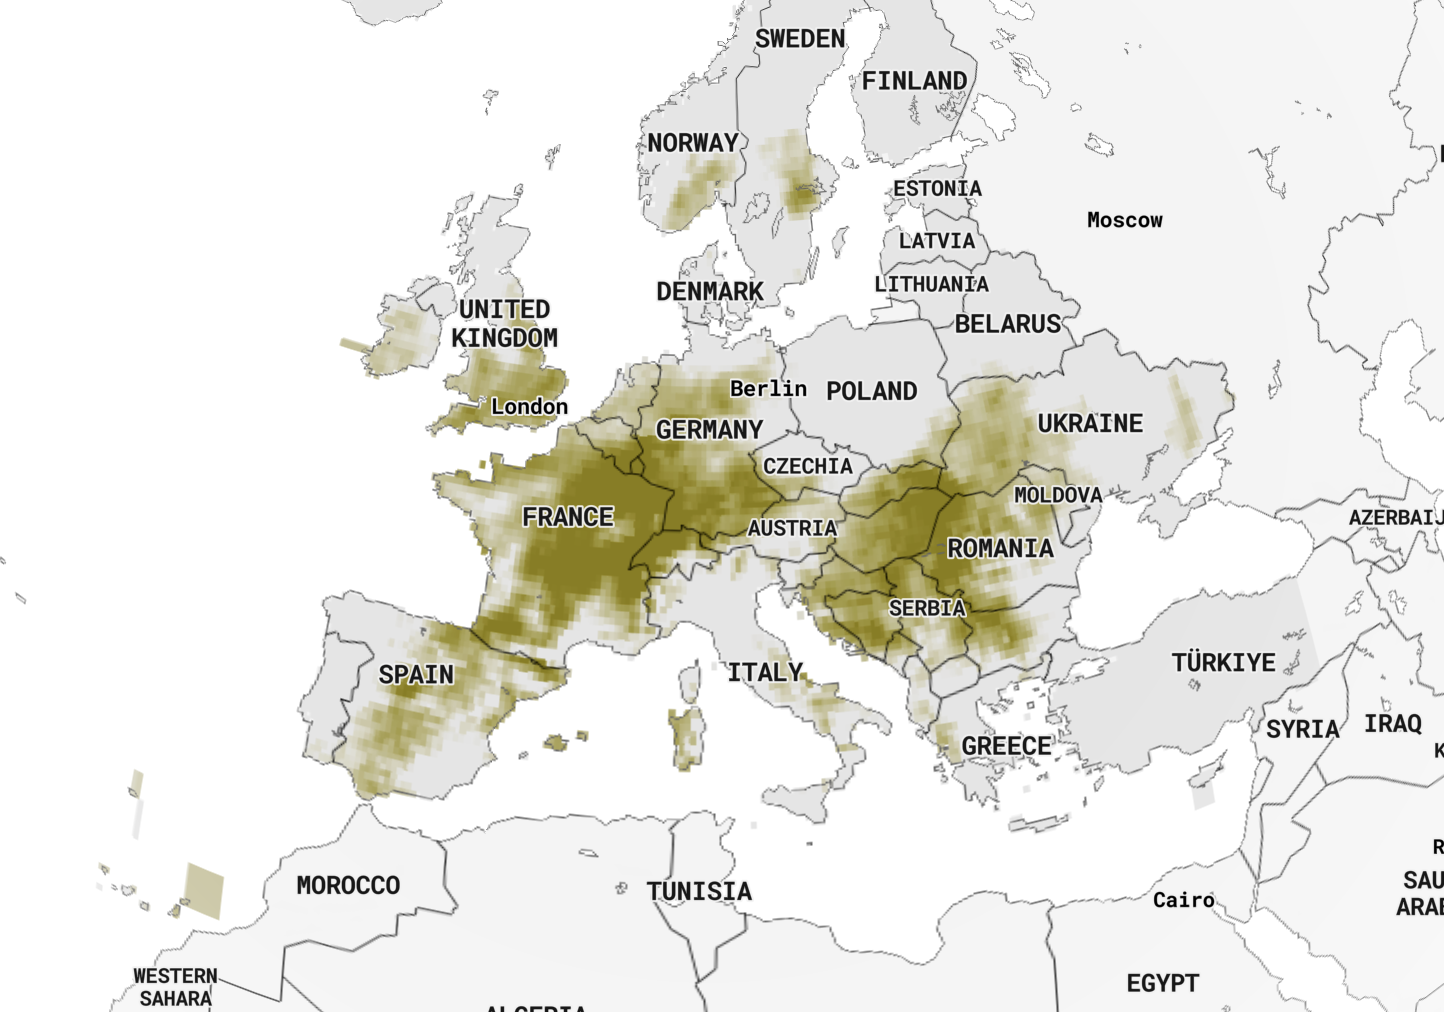

---
# Drought - test title
More charts for those who want to go further. They work like the ones above: run them from top to bottom.


### Part A · Guided tour
*European Extreme Events Climate Index · hands-on workshop · Visualising Climate 2026, Bologna*

Europe is living through more frequent and more intense extreme events. In this notebook we explore together
**46 years of monthly data (January 1981 – August 2026) for 51 countries** and, for every chart, we ask one question:
***what message does it communicate?***

**In this notebook you don't need to change anything:** run the cells one after the other, look at the charts and
join the discussion. In the second part of the workshop you will work on a copy of this notebook, connected to the
[Climate Gazette](https://gazette.climateindex.eu/): you will choose the charts for your story, change the country,
the component or the month, and add your own text.

First the charts about **all the European countries**, then those about **one country and its regions**:

| Part | Question | Time |
|---|---|---|
| **0 · Setup** | Run 5 cells | 3 min |
| **1 · Europe** | Is Europe getting more extreme? When in the year? | 8 min |
| **2 · Compare countries** | Who is hit the hardest? | 7 min |
| **3 · One country** | What happened in Italy, and in its regions? | 12 min |
| **⭐ Extra** | More charts to explore on your own, after the tour | – |

### How to use this notebook
* **Before you start:** sign in with a Google account and use **File → Save a copy in Drive** to keep your work.
  If Colab warns that the notebook was "not authored by Google", click **Run anyway**.
* Run the cells **one at a time, from top to bottom**: click ▶ on the left of a cell, or press **Shift + Enter**.
* The code of every chart is visible, so you can see how it is made, but there is **nothing to change**: the settings
  at the top of each cell (country, component, month…) are fixed for this guided tour.
* Something went wrong? Read the **last line** of the red message. If Colab restarted, click the cell you were on and
  use **Runtime → Run before**.
* Every chart is also saved in the folder `my_figures` (📁 icon on the left).

### How to read the E3CI in one minute
* For every **month**, **place** and **component**, the E3CI compares that month with the **same month in 1981–2010**.
  It is a *standardised anomaly*: **0 = a normal month**, 1 = one standard deviation above normal.
* Following the E3CI Data Station, **values above 1 are extreme**, in three classes: **1–2, 2–3, above 3**.
* Some values reach the hundreds, even about 2,000. Where an event almost never happened in 1981–2010 (heavy rain
  in a desert summer, fire weather in Ireland), even a moderate event looks gigantic on this scale.
  That's one reason why the Data Station shows **classes** rather than raw numbers.
* **Fire** is not computed where and when fire danger practically never occurs (e.g. winter in northern Europe):
  those months are empty, and fire statistics use only the months in which it is computed.

*Data: E3CI – European Extreme Events Climate Index, [climateindex.eu](https://www.climateindex.eu), computed from the
Copernicus Climate Change Service ERA5 reanalysis. Explore it at the [Data Station](https://datastation.climateindex.eu).*

## 0 · Setup ⏱ 3 min
Run these five cells once (click "Show code" if you are curious). Colab asks for **two data files**: in the second
cell upload **aci_comps_2026August.csv** (the 51 countries, 2.4 MB), in the fifth one
**aci_comps_gaul_2026August.csv** (the ≈750 regions used in Part 3, 35 MB). You can also drag both files onto the
📁 Files panel before you start, unless your organisers have already put a link in `DATA_URL`.
The third cell checks the data and sets aside a few periods that look like processing gaps: real data always need
checking before we draw them!

In [ ]:
# @title ⚙️ Setup 1/5 · Libraries (≈10 seconds)

import importlib.util, subprocess, sys

# # Google Colab already has almost everything: install only what is missing
# for package in ["geopandas", "plotly"]:
#     if importlib.util.find_spec(package) is None:
#         print(f"Installing {package} ...")
#         subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

import difflib
import os
import shutil
import textwrap
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib import font_manager
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import geopandas as gpd
from IPython.display import Image, display

warnings.filterwarnings("ignore", category=RuntimeWarning)   # e.g. "mean of empty slice"
warnings.filterwarnings("ignore", category=FutureWarning)

IN_COLAB = "google.colab" in sys.modules
print("✔ Libraries ready", "(Google Colab)" if IN_COLAB else "(local Jupyter)")


✔ Libraries ready (Google Colab)


In [ ]:
# @title ⚙️ Setup 2/5 · Load the E3CI data

NATIONAL_FILE = "aci_comps_2026August.csv"        # 51 countries
REGIONAL_FILE = "aci_comps_gaul_2026August.csv"   # ~750 regions (GAUL level 1), loaded in Setup 5/5

# 👉 Organisers: if the CSV files are online, paste the link of their folder here (ending with "/"),
#    e.g. "https://raw.githubusercontent.com/<user>/<repo>/main/data/". Leave "" to upload them by hand.
DATA_URL = ""


def get_data_file(filename):
    """Find `filename` (also as .gz) on disk; otherwise download it from DATA_URL or ask to upload it."""
    for folder in [".", "data", "/content", "/content/data", "/content/drive/MyDrive"]:
        for name in [filename, filename + ".gz"]:
            path = os.path.join(folder, name)
            if os.path.exists(path):
                return path
    if DATA_URL:
        for name in [filename, filename + ".gz"]:          # the organisers may have shared a .gz version
            try:
                print(f"Downloading {name} ...")
                urllib.request.urlretrieve(DATA_URL + name, name)
                return name
            except Exception as error:
                print(f"  (not found: {error})")
    help_text = (f"Upload {filename}: drag it onto the 📁 Files panel on the left "
                 f"(or use the upload button below), then run this cell again.")
    if IN_COLAB:
        from google.colab import files
        print("👉", help_text)
        uploaded = files.upload()
        for name in uploaded:
            if name.startswith(filename.split(".")[0]) and (name.endswith(".csv") or name.endswith(".gz")):
                target = filename + ".gz" if name.endswith(".gz") else filename
                if name != target:
                    os.rename(name, target)
                return target
        raise FileNotFoundError(f"{filename} was not uploaded. " + help_text)
    raise FileNotFoundError(f"{filename} not found: put it next to this notebook or set DATA_URL.")


def read_e3ci_csv(path):
    """Read an E3CI CSV: 2 header rows (area, component), one row per month, ';' as separator."""
    table = pd.read_csv(path, sep=";", header=[0, 1], index_col=0,
                        na_values=[" ", ""], low_memory=False)
    # The area name is written only above the first of its 7 columns: carry it forward
    areas = []
    current_area = None
    for name in table.columns.get_level_values(0):
        if not str(name).startswith("Unnamed"):
            current_area = name
        areas.append(current_area)
    components = list(table.columns.get_level_values(1))
    table.columns = pd.MultiIndex.from_arrays([areas, components], names=["area", "component"])
    table.index = pd.to_datetime(table.index)
    table.index.name = "time"
    table = table.apply(pd.to_numeric, errors="coerce")
    # A few months appear twice in the file: keep the last (most recent) version
    n_duplicates = int(table.index.duplicated().sum())
    table = table[~table.index.duplicated(keep="last")]
    if n_duplicates > 0:
        print(f"  ℹ️ {n_duplicates} duplicated month(s) found in {os.path.basename(path)}: kept the latest version")
    return table


national = read_e3ci_csv(get_data_file(NATIONAL_FILE))

COUNTRIES = sorted(national.columns.get_level_values("area").unique())
MEDITERRANEAN_NEIGHBOURS = ["Israel", "Jordan", "Lebanon", "Morocco", "Palestine", "Tunisia"]
EUROPE = [c for c in COUNTRIES if c not in MEDITERRANEAN_NEIGHBOURS]   # the 45 countries of the Data Station

FIRST_YEAR = int(national.index.year.min())
LAST_YEAR = int(national.index.year.max())
LAST_DATE = national.index.max()

print(f"✔ National data: {len(COUNTRIES)} countries × 7 components, "
      f"{national.index.min():%B %Y} → {LAST_DATE:%B %Y} ({len(national)} months)")
print("  Countries:", ", ".join(COUNTRIES))


👉 Upload aci_comps_2026August.csv: drag it onto the 📁 Files panel on the left (or use the upload button below), then run this cell again.


Saving aci_comps_gaul_2026August.csv to aci_comps_gaul_2026August.csv
Saving aci_comps_2026August.csv to aci_comps_2026August.csv
  ℹ️ 3 duplicated month(s) found in aci_comps_2026August.csv: kept the latest version
✔ National data: 51 countries × 7 components, January 1981 → August 2026 (548 months)
  Countries: Albania, Andorra, Austria, Belarus, Belgium, Bosnia and Herzegovina, Bulgaria, Croatia, Cyprus, Czechia, Denmark, Estonia, Faroes, Finland, France, Germany, Greece, Guernsey, Hungary, Iceland, Ireland, Isle of Man, Israel, Italy, Jersey, Jordan, Latvia, Lebanon, Lithuania, Luxembourg, Malta, Moldova, Montenegro, Morocco, Netherlands, North Macedonia, Norway, Palestine, Poland, Portugal, Romania, Serbia, Slovakia, Slovenia, Spain, Sweden, Switzerland, Tunisia, Turkey, Ukraine, United Kingdom


In [ ]:
# @title ⚙️ Setup 3/5 · Data check
# In this version of the file a few periods look like processing gaps rather than real weather
# (no country at all with fire extremes after 2024, even in summer; hail and some rainfall months with
# every country at its minimum at the same time). We treat them as missing.
# If you get a corrected file, simply set KNOWN_GAPS = {}.

KNOWN_GAPS = {
    "fire":         [("2025-01", "2026-08")],
    "hail":         [("1985-01", "1985-12"), ("2022-01", "2022-12")],
    "extreme prec": [("2020-04", "2020-04"), ("2020-11", "2020-12"), ("2022-01", "2022-01"), ("2022-08", "2022-08")],
    # drought uses 3-month rainfall (SPI-3): the three months after each rainfall gap are affected too
    "drought":      [("2020-04", "2020-06"), ("2020-11", "2021-02"), ("2022-01", "2022-03"), ("2022-08", "2022-10")],
}


def apply_known_gaps(table, gaps, verbose=True):
    """Set the listed (component, period) cells to NaN = 'missing'."""
    table = table.copy()
    components = table.columns.get_level_values("component")
    for component, periods in gaps.items():
        for start, end in periods:
            rows = (table.index >= pd.Timestamp(start)) & (table.index < pd.Timestamp(end) + pd.offsets.MonthBegin(1))
            table.loc[rows, components == component] = np.nan
            if verbose and rows.any():
                print(f"  · {component:13s} {start} → {end}: treated as missing")
    return table


def years_with_gaps():
    """Years in which at least one component has missing data (see the data check)."""
    years = set()
    for component, periods in KNOWN_GAPS.items():
        for start, end in periods:
            for year in range(int(start[:4]), int(end[:4]) + 1):
                years.add(year)
    return sorted(years)


def gaps_note():
    """A short footnote listing the known data gaps, e.g. 'fire 2025–2026 · hail 1985, 2022'."""
    parts = []
    for component, periods in KNOWN_GAPS.items():
        years = sorted({y for start, end in periods for y in range(int(start[:4]), int(end[:4]) + 1)})
        parts.append(f"{COMPONENTS[component]['short'].lower()} {', '.join(str(y) for y in years)}")
    return "* incomplete data (see the data check): " + " · ".join(parts) if parts else None


national = apply_known_gaps(national, KNOWN_GAPS)
print("✔ Data check done")


  · fire          2025-01 → 2026-08: treated as missing
  · hail          1985-01 → 1985-12: treated as missing
  · hail          2022-01 → 2022-12: treated as missing
  · extreme prec  2020-04 → 2020-04: treated as missing
  · extreme prec  2020-11 → 2020-12: treated as missing
  · extreme prec  2022-01 → 2022-01: treated as missing
  · extreme prec  2022-08 → 2022-08: treated as missing
  · drought       2020-04 → 2020-06: treated as missing
  · drought       2020-11 → 2021-02: treated as missing
  · drought       2022-01 → 2022-03: treated as missing
  · drought       2022-08 → 2022-10: treated as missing
✔ Data check done


In [ ]:
# @title ⚙️ Setup 4/5 · Colours, style and small helper functions

# The 7 components, in the order used in every chart, with the colours of the E3CI Data Station.
# Each component has 4 shades, one per E3CI class: [≤ 1, 1–2, 2–3, > 3]
COMPONENTS = {
    "extreme max T": {"label": "Extreme max temperature", "short": "Max temperature",
                      "colors": ["#E6E6E6", "#EFB598", "#E88754", "#D15400"]},
    "extreme min T": {"label": "Extreme min temperature", "short": "Min temperature",
                      "colors": ["#E6E6E6", "#B2C9D7", "#75ABC8", "#008AB8"]},
    "drought":       {"label": "Drought", "short": "Drought",
                      "colors": ["#E6E6E6", "#CBC69C", "#ABA357", "#8A7C00"]},
    "extreme prec":  {"label": "Extreme precipitation", "short": "Precipitation",
                      "colors": ["#E6E6E6", "#A3B7E3", "#5380E4", "#0500FF"]},
    "extreme wind":  {"label": "Extreme wind", "short": "Wind",
                      "colors": ["#E6E6E6", "#F4B1D7", "#F575C8", "#EB00B8"]},
    "hail":          {"label": "Hail", "short": "Hail",
                      "colors": ["#E6E6E6", "#C9B5E9", "#A97CEF", "#8F00FF"]},
    "fire":          {"label": "Fire", "short": "Fire",
                      "colors": ["#E6E6E6", "#FFB2A0", "#FF7C62", "#FF0000"]},
}
COMPONENT_ORDER = list(COMPONENTS)
for component in COMPONENTS:
    COMPONENTS[component]["color"] = COMPONENTS[component]["colors"][-1]   # the full colour

CLASS_LABELS = ["≤ 1", "1 – 2", "2 – 3", "> 3"]
MONTH_NAMES = ["January", "February", "March", "April", "May", "June", "July",
               "August", "September", "October", "November", "December"]
MONTH_ABBR = [m[:3] for m in MONTH_NAMES]
BASELINE = (1981, 2010)          # the E3CI reference period
RECENT = (2011, LAST_YEAR)       # the most recent years, used for "then vs now" comparisons

INK, INK_2, INK_3 = "#1F1F1F", "#5C5C5C", "#8C8C8C"     # text: primary, secondary, muted
GRID, AXIS, NO_DATA = "#EBEBEB", "#C4C4C4", "#F6F6F6"
SOURCE = "Data: E3CI – European Extreme Events Climate Index (climateindex.eu), based on Copernicus ERA5"


def use_nice_font():
    """Use the free Lato font if it can be downloaded, otherwise keep the default one."""
    base = "https://raw.githubusercontent.com/google/fonts/main/ofl/lato/"
    os.makedirs("fonts", exist_ok=True)
    try:
        for name in ["Lato-Regular.ttf", "Lato-Bold.ttf"]:
            path = os.path.join("fonts", name)
            if not os.path.exists(path):
                urllib.request.urlretrieve(base + name, path)
            font_manager.fontManager.addfont(path)
        return ["Lato", "DejaVu Sans"]
    except Exception:
        return ["DejaVu Sans"]


plt.rcParams.update({
    "font.family": use_nice_font(), "font.size": 10.5,
    "figure.dpi": 110, "savefig.dpi": 200, "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK_2,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": INK, "xtick.color": AXIS, "ytick.color": AXIS,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "grid.color": GRID, "grid.linewidth": 0.8, "legend.frameon": False,
})


def check_name(name, valid, what):
    """Stop with a helpful message when a name is misspelled (it happens to everyone!)."""
    if name not in valid:
        close = difflib.get_close_matches(str(name), [str(v) for v in valid], n=3, cutoff=0.5)
        hint = f" Did you mean {' or '.join(repr(c) for c in close)}?" if close else ""
        raise ValueError(f"{name!r} is not a valid {what}.{hint}")


def table(component, areas=None, data=None):
    """All values of one component: rows = months, columns = areas."""
    data = national if data is None else data
    check_name(component, list(COMPONENTS), "component")
    result = data.xs(component, axis=1, level="component")
    if isinstance(areas, str):                      # a single name is fine too
        areas = [areas]
    if areas is not None:
        for area in areas:
            check_name(area, result.columns, "country or region name")
        result = result[areas]
    return result


def series(area, component, data=None):
    """Monthly values of one component in one area (a pandas Series indexed by date)."""
    data = national if data is None else data
    check_name(component, list(COMPONENTS), "component")
    check_name(area, data.columns.get_level_values("area").unique(), "country or region name")
    return data[(area, component)]


def default_areas(areas, data=None):
    """The areas to compare: EUROPE (countries) or EUROPE_REGIONS (regions), unless chosen."""
    if areas is None:
        return EUROPE if data is None or data is national else EUROPE_REGIONS
    return [areas] if isinstance(areas, str) else list(areas)


def data_for(areas):
    """The data that contains these names: national for countries, regional for regions."""
    names = [areas] if isinstance(areas, str) else list(areas)
    if all(name in COUNTRIES for name in names):
        return national
    if "regional" in globals() and all(name in REGIONS for name in names):
        return regional
    if "regional" in globals() and all(name in COUNTRIES or name in REGIONS for name in names):
        raise ValueError("Countries and regions can't be mixed in the same chart: use only countries or only regions.")
    return national                       # unknown names: table() will say which one and suggest a fix


def has_data(values, area, component):
    """False (with a message) when a place has no data at all for a component."""
    if values.dropna().empty:
        print(f"⚠️ No {COMPONENTS[component]['label'].lower()} data for {area}: try another component or place.")
        return False
    return True


def hatch_missing(ax, xs, ys, grid):
    """Grey hatching on the cells of a heatmap without data (NaN)."""
    for i, y in enumerate(ys):
        for j, x in enumerate(xs):
            if np.isnan(grid[i, j]):
                ax.add_patch(plt.Rectangle((x - 0.5, y - 0.5), 1, 1, facecolor="white", edgecolor=AXIS,
                                           hatch="////", linewidth=0))


def no_data_patch(label="no data"):
    return Patch(facecolor="white", edgecolor=AXIS, hatch="////", linewidth=0, label=label)


def format_pct(x):
    """12.3 -> '12%', 4.56 -> '4.6%' (one decimal for small shares)."""
    return f"{x:.0f}%" if x >= 10 else f"{x:.1f}%"


def format_change(then, now):
    """'then → now (×ratio)'; the ratio is left out when the starting value is too small to divide by."""
    text = f"{format_pct(then)} → {format_pct(now)}"
    if then >= 0.5:
        text += f"  (×{now / then:.1f})"
    return text


def in_period(index, period):
    """True for the dates whose year is inside period = (first_year, last_year)."""
    return (index.year >= period[0]) & (index.year <= period[1])


def e3ci_class(values):
    """E3CI class of each value: 0 = ≤1 (no extreme), 1 = 1–2, 2 = 2–3, 3 = >3. NaN stays NaN."""
    values = np.asarray(values, dtype=float)
    classes = np.full(values.shape, np.nan)
    classes[values <= 1] = 0
    classes[(values > 1) & (values <= 2)] = 1
    classes[(values > 2) & (values <= 3)] = 2
    classes[values > 3] = 3
    return classes


def class_cmap(component):
    """Colour map + norm to draw E3CI classes (0–3) with the colours of a component."""
    cmap = mcolors.ListedColormap(COMPONENTS[component]["colors"])
    cmap.set_bad("white")
    norm = mcolors.BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5], cmap.N)
    return cmap, norm


def class_legend(component):
    """Legend handles for the 4 classes of a component."""
    handles = []
    for color, label in zip(COMPONENTS[component]["colors"], CLASS_LABELS):
        handles.append(Patch(facecolor=color, edgecolor="none", label=label))
    return handles


def add_titles(fig, title, subtitle=None):
    """Title + subtitle above the figure, left-aligned (the story first!)."""
    height = fig.get_figheight()
    if subtitle:                                   # wrap long subtitles to the width of the figure
        width = int(fig.get_figwidth() * 12)
        subtitle = "\n".join(textwrap.fill(line, width) for line in subtitle.split("\n"))
    n_lines = 0 if subtitle is None else subtitle.count("\n") + 1
    if subtitle:
        fig.text(0.0, 1 + 0.12 / height, subtitle, ha="left", va="bottom",
                 fontsize=11, color=INK_2, linespacing=1.4)
    fig.text(0.0, 1 + (0.2 + 0.26 * n_lines) / height, title, ha="left", va="bottom",
             fontsize=16, fontweight="bold", color=INK)


def add_source(fig, note=None):
    """Source line (and an optional note) below the figure."""
    height = fig.get_figheight()
    text = SOURCE if note is None else note + "\n" + SOURCE
    fig.text(0.0, -0.18 / height, text, ha="left", va="top", fontsize=8.5, color=INK_3, linespacing=1.5)


def save_figure(fig, *name_parts):
    """Save the figure as a PNG in the folder my_figures/ (to share it at the end)."""
    os.makedirs("my_figures", exist_ok=True)
    name = "_".join(str(p) for p in name_parts)
    for char in " /()'":
        name = name.replace(char, "-")
    path = os.path.join("my_figures", name + ".png")
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    return path


print("✔ Style ready — font:", plt.rcParams["font.family"][0])


✔ Style ready — font: Lato


In [ ]:
# @title ⚙️ Setup 5/5 · Regional data (≈750 regions, GAUL level 1) · takes a few seconds
regional = read_e3ci_csv(get_data_file(REGIONAL_FILE))
regional = apply_known_gaps(regional, KNOWN_GAPS, verbose=False)
REGIONS = sorted(regional.columns.get_level_values("area").unique())

# Regions of the Mediterranean neighbours (Jordan, Israel, Palestine, Lebanon, Syria, Libya, Tunisia, Morocco)
# and two special units: we leave them out when we compare European regions
OUTSIDE_EUROPE = [
    "Ajloun", "Al Aqabah", "Al Balqa", "Al Karak", "Al Khalil (Hebron)", "Al Mafraq", "Al Quds (Jerusalem)",
    "Al_Qunaytirah", "Amman", "Ariha (Jericho)", "At Tafilah", "Az Zarqa", "Ben Arous", "Beqaa", "Bizerte",
    "Central District", "Centre Nord", "Centre Sud", "City_Damascus", "Gabes", "Gafsa", "Gaza", "Haifa",
    "Irbid", "Jendouba", "Jenin", "Jerusalem", "Kairouan", "Kasserine", "Kebili", "Lattakia", "Le Kef",
    "Liban Nord", "Liban Sud", "Ma'an", "Madaba", "Mahdia", "Manouba", "Medenine", "Monastir", "Mont Liban",
    "Nabatieh", "Nabeul", "Nablus", "Nord Ouest", "Northern", "Nuqat Al Khams", "Oriental", "Ramallah",
    "Sfax", "Sidi Bouz", "Siliana", "Sousse", "Southern District", "Sud", "Tartous", "Tataouine", "Tensift",
    "Tozeur", "Tubas", "Zaghouan",
    "United Kingdom",                      # the UK sovereign bases in Cyprus
    "Administrative unit not available",
]
EUROPE_REGIONS = [r for r in REGIONS if r not in OUTSIDE_EUROPE]
ITALIAN_REGIONS = ["Abruzzi", "Basilicata", "Calabria", "Campania", "Emilia-romagna", "Friuli-venezia Giulia",
                   "Lazio", "Liguria", "Lombardia", "Marche", "Molise", "Piemonte", "Puglia", "Sardegna",
                   "Sicilia", "Toscana", "Trentino-alto Adige", "Umbria", "Valle D'aosta", "Veneto"]
print(f"✔ Regional data: {len(REGIONS)} regions ({len(EUROPE_REGIONS)} in Europe)")


def find_area(text):
    """Search countries and regions whose name contains `text` (e.g. find_area('emilia'))."""
    text = text.lower()
    countries = [c for c in COUNTRIES if text in c.lower()]
    regions = [r for r in REGIONS if text in r.lower()]
    print("countries:", countries if countries else "—")
    print("regions:  ", regions if regions else "—")


  ℹ️ 3 duplicated month(s) found in aci_comps_gaul_2026August.csv: kept the latest version
✔ Regional data: 750 regions (687 in Europe)


## 1 · Europe: is it getting more extreme? ⏱ 8 min
We count the **country-months** above 1: one country in extreme heat for one month = 1.
With 45 countries and 12 months, a year has 540 country-months for each component.

### 1.1 Each hazard has its own story
One small chart per component (*small multiples*): every bar is the share of country-months above 1 in one year,
the dashed line is the average of 1981–2010.

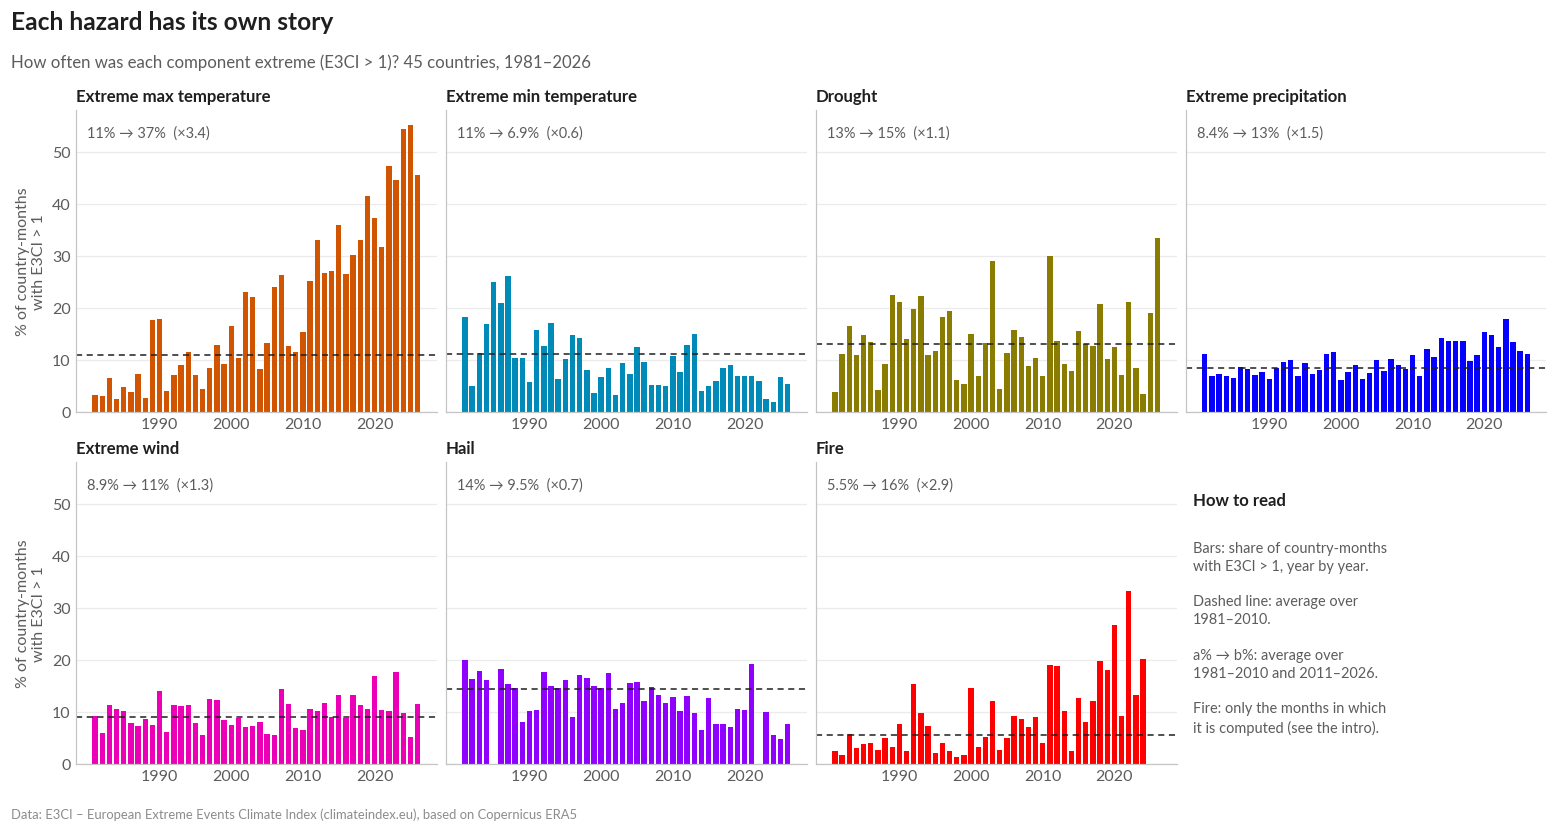

In [ ]:
# Settings of this chart
THRESHOLD = 1
AREAS = EUROPE
TITLE = ""   # your title between the quotes, or "" for the automatic title


def plot_hazard_trends(threshold=1, areas=EUROPE, title=None, subtitle=None):
    years = np.arange(FIRST_YEAR, LAST_YEAR + 1)
    fig, axes = plt.subplots(2, 4, figsize=(14, 6.4), sharex=True, sharey=True, layout="constrained")
    axes = axes.ravel()

    for i, component in enumerate(COMPONENT_ORDER):
        ax = axes[i]
        values = table(component, areas)
        n_extreme = (values > threshold).sum(axis=1).groupby(values.index.year).sum()
        n_valid = values.notna().sum(axis=1).groupby(values.index.year).sum()
        share = (100 * n_extreme / n_valid.where(n_valid > 0)).reindex(years)   # % of country-months

        baseline = share[(years >= BASELINE[0]) & (years <= BASELINE[1])].mean()
        recent = share[(years >= RECENT[0]) & (years <= RECENT[1])].mean()

        ax.bar(years, share, width=0.75, color=COMPONENTS[component]["color"], edgecolor="none")
        ax.axhline(baseline, color=INK, linewidth=1, linestyle=(0, (4, 3)))
        ax.set_title(f"{COMPONENTS[component]['label']}", fontsize=11)
        ax.text(0.03, 0.95, format_change(baseline, recent),
                transform=ax.transAxes, fontsize=9.5, color=INK_2, va="top")
        ax.grid(axis="y")
        ax.set_axisbelow(True)
        ax.tick_params(length=0)
        ax.set_xticks([1990, 2000, 2010, 2020])

    # The 8th panel explains how to read the others
    note = axes[-1]
    note.axis("off")
    note.text(0.02, 0.9, "How to read", fontsize=11, fontweight="bold", color=INK, transform=note.transAxes, va="top")
    note.text(0.02, 0.74,
              f"Bars: share of country-months\nwith E3CI > {threshold}, year by year.\n\n"
              f"Dashed line: average over\n{BASELINE[0]}–{BASELINE[1]}.\n\n"
              f"a% → b%: average over\n{BASELINE[0]}–{BASELINE[1]} and {RECENT[0]}–{RECENT[1]}.\n\n"
              "Fire: only the months in which\nit is computed (see the intro).",
              fontsize=9.5, color=INK_2, transform=note.transAxes, va="top", linespacing=1.35)
    for ax in axes[:4]:
        ax.tick_params(labelbottom=True)
    for ax in [axes[0], axes[4]]:
        ax.set_ylabel(f"% of country-months\nwith E3CI > {threshold}")

    add_titles(fig, title or "Each hazard has its own story",
               subtitle or f"How often was each component extreme (E3CI > {threshold})? "
                           f"{len(areas)} countries, {FIRST_YEAR}–{LAST_YEAR}")
    add_source(fig)
    save_figure(fig, "02_hazard_trends", f"threshold{threshold}")
    plt.show()


plot_hazard_trends(THRESHOLD, AREAS, title=TITLE)


💬 Since 2011, months of extreme heat have been **more than 3 times** as frequent as in 1981–2010, and fire-weather
extremes almost 3 times, while cold extremes and hail have become rarer. Precipitation, wind and drought change less,
and less regularly: trends in these hazards are harder to detect than in temperature.

Now let's look at the same hazards from another angle: **when in the year** do they strike?

### 1.2 When in the year?
A *rose* for each hazard and period, inspired by Florence Nightingale's diagrams (1858). **How to read it:**
* every petal is a **calendar month**: January at the top, then clockwise (April on the right, July at the bottom,
  October on the left);
* the **area** of a petal, not its length, is proportional to the share of country-months that were extreme in that
  month, as in Nightingale's roses;
* inside each petal the classes go **from the centre outwards**: 1–2 (the lightest shade), 2–3, above 3 (the darkest);
* top row: 1981–2010; bottom row: since 2011.

Remember: an E3CI "heat extreme" in January is an unusually **warm January**, not a 40 °C day.

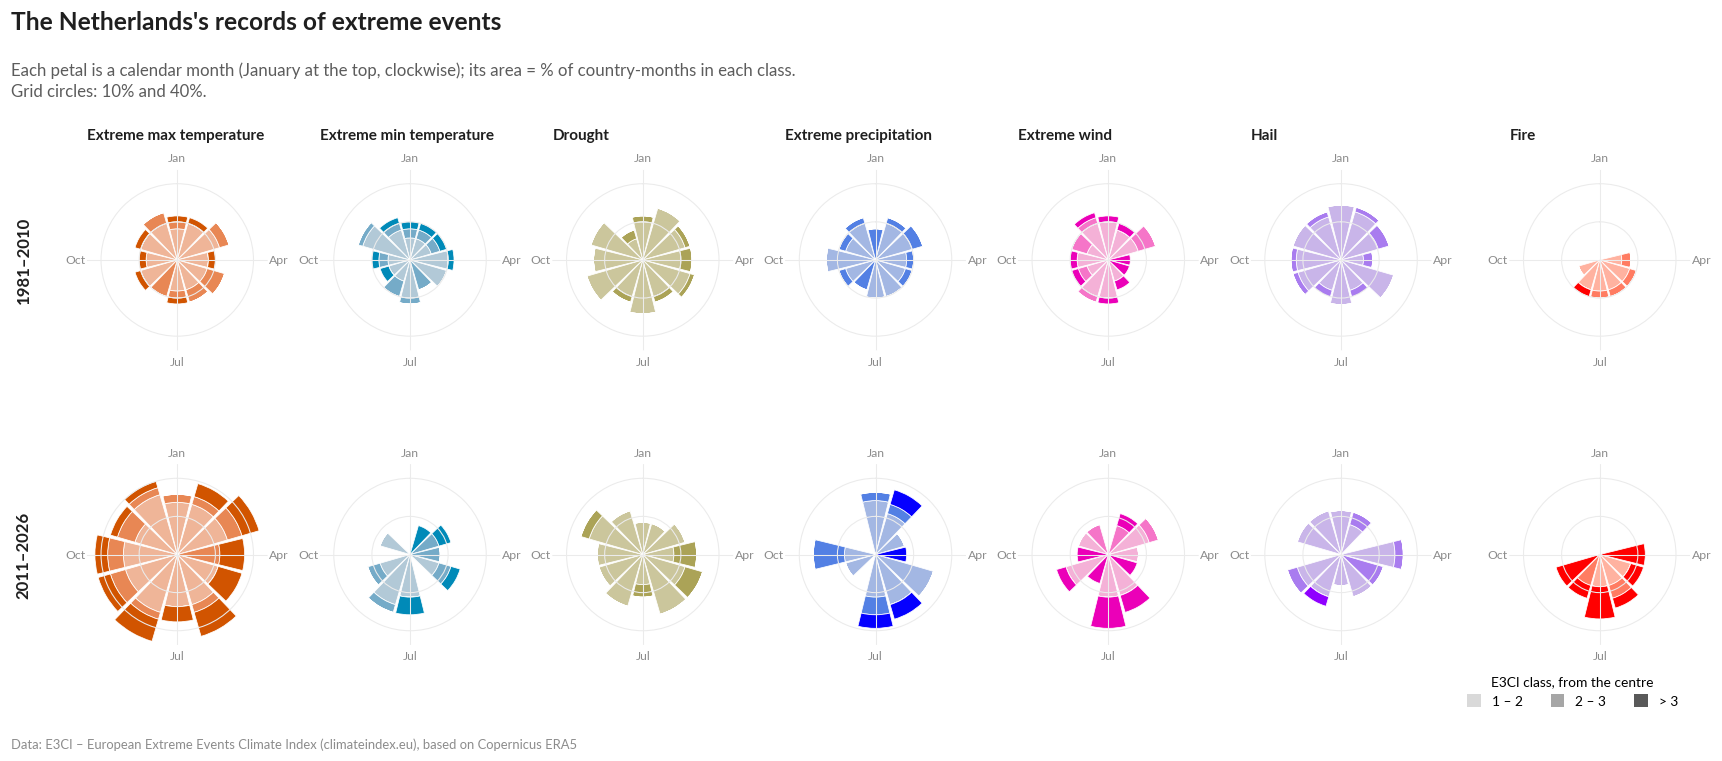

In [ ]:
# Settings of this chart
PERIODS = [BASELINE, RECENT]      # e.g. [(1981, 1990), (2017, 2026)] to compare the first and last decade
AREAS = "Netherlands"                    # or a single country, e.g. ["Italy"]
TITLE = "The Netherlands's records of extreme events"   # your title between the quotes, or "" for the automatic title


def plot_roses(periods, areas=EUROPE, data=None, title=None, subtitle=None):
    angles = np.linspace(0, 2 * np.pi, 12, endpoint=False)
    class_ranges = [(1, 2), (2, 3), (3, np.inf)]

    # 1. % of country-months in each class, for each component, period and calendar month
    shares = {}
    for component in COMPONENT_ORDER:
        values = table(component, areas, data)
        for period in periods:
            sub = values[in_period(values.index, period)]
            result = np.zeros((3, 12))
            for month in range(1, 13):
                month_values = sub[sub.index.month == month]
                n_valid = month_values.notna().sum().sum()
                for k, (low, high) in enumerate(class_ranges):
                    n_class = ((month_values > low) & (month_values <= high)).sum().sum()
                    result[k, month - 1] = 100 * n_class / max(n_valid, 1)
            shares[(component, period)] = result
    r_max = np.sqrt(max(s.sum(axis=0).max() for s in shares.values()))

    # 2. One rose per component and period. Radius = square root, so that the AREA of each petal
    #    is proportional to the value (as in Florence Nightingale's famous roses, 1858)
    fig, axes = plt.subplots(len(periods), 7, figsize=(15.5, 2.55 * len(periods) + 0.4),
                             subplot_kw={"projection": "polar"}, layout="constrained")
    axes = np.atleast_2d(axes)
    for col, component in enumerate(COMPONENT_ORDER):
        for row, period in enumerate(periods):
            ax = axes[row, col]
            cumulative = np.zeros(12)
            for k in range(3):
                bottom = np.sqrt(cumulative)
                cumulative = cumulative + shares[(component, period)][k]
                ax.bar(angles, np.sqrt(cumulative) - bottom, bottom=bottom, width=2 * np.pi / 12 * 0.92,
                       color=COMPONENTS[component]["colors"][k + 1], edgecolor="white", linewidth=0.5)
            ax.set_theta_zero_location("N")
            ax.set_theta_direction(-1)
            ax.set_ylim(0, r_max)
            ax.set_xticks(angles[::3], ["Jan", "Apr", "Jul", "Oct"], fontsize=8, color=INK_3)
            ax.set_yticks([np.sqrt(10), np.sqrt(40)], [])
            ax.grid(color=GRID, linewidth=0.7)
            ax.spines["polar"].set_visible(False)
            ax.tick_params(pad=-3)
            if row == 0:
                ax.set_title(COMPONENTS[component]["label"], fontsize=10, pad=20)
            if col == 0:
                ax.text(-0.35, 0.5, f"{period[0]}–{period[1]}", transform=ax.transAxes, rotation=90,
                        ha="center", va="center", fontsize=11, fontweight="bold", color=INK)
    greys = ["#D9D9D9", "#A6A6A6", "#595959"]
    axes[-1, -1].legend(handles=[Patch(facecolor=g, label=l) for g, l in zip(greys, CLASS_LABELS[1:])],
                        title="E3CI class, from the centre", loc="upper right", bbox_to_anchor=(1.0, -0.1),
                        ncol=3, fontsize=9, title_fontsize=9, handlelength=1, handleheight=1)
    add_titles(fig, title or "When in the year do extremes strike?",
               subtitle or "Each petal is a calendar month (January at the top, clockwise); its area = % of "
                           "country-months in each class.\nGrid circles: 10% and 40%.")
    add_source(fig)
    save_figure(fig, "10_roses")
    plt.show()


plot_roses(PERIODS, AREAS, title=TITLE)


💬 In 1981–2010 most roses are almost round: the E3CI measures every month against the same month of that period.
Since 2011 the extreme-heat rose has grown **in every direction**: in every calendar month, from a quarter to almost
half of the country-months were extreme, against about one in ten before. Fire weather grows above all in spring and
summer (in April, from 5% to 20% of the country-months), while the cold rose shrinks, especially in summer and in late
autumn.

---
## 2 · Compare countries: who is hit the hardest? ⏱ 7 min
From here on, every chart looks at **one component** (or two) or at **one place**: in this guided tour we chose
extreme heat, July and Italy, and the settings at the top of each cell can show any other.

### 2.1 One month, all countries
Extreme heat in **July**: every row is a country, every cell a year. On the right, how many extreme Julys each
country had since 1981: the countries with the most are at the top.

*Why July?* It is the heart of summer, when heat extremes hit people the hardest. But the E3CI compares every July
only with the Julys of 1981–2010, so any other month can be read in the same way: in the second part of the workshop
you can choose it (`MONTH = 0` shows the strongest month of each year).

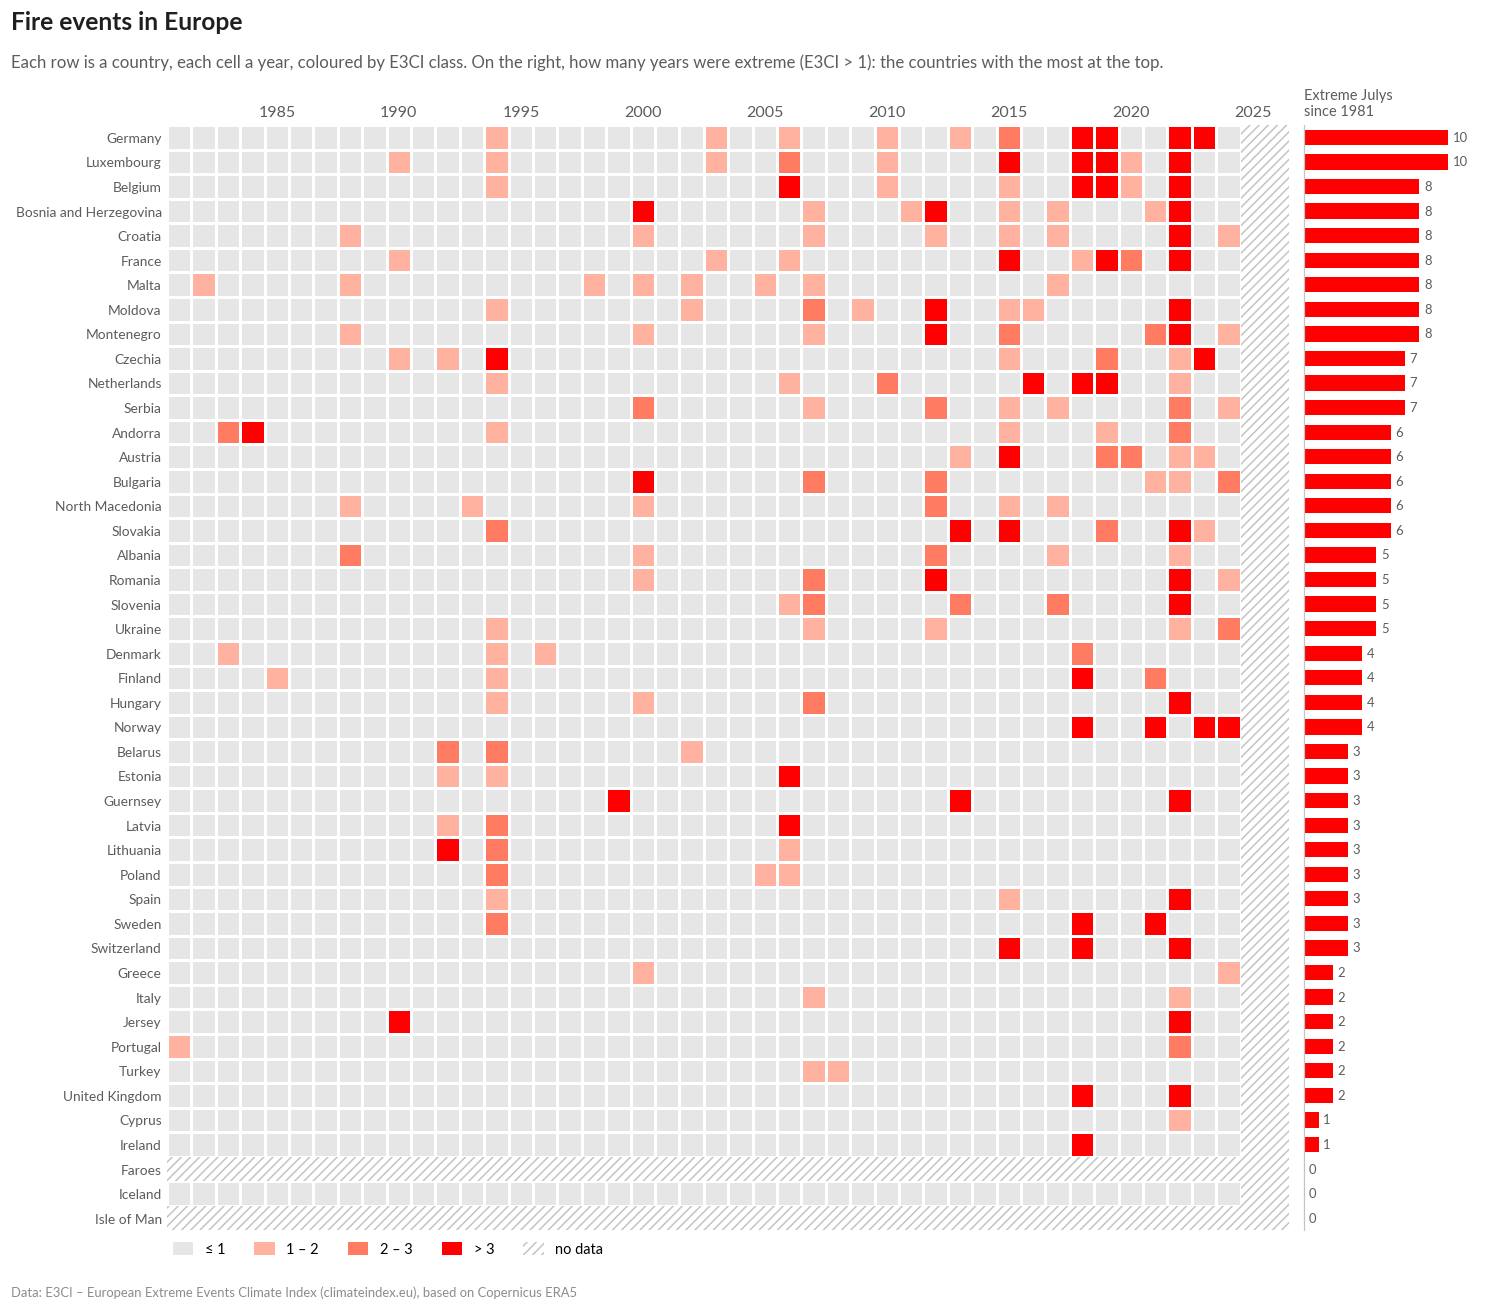

In [ ]:
# Settings of this chart
COMPONENT = "fire"
MONTH = 7
SORT_BY = "count"
# MONTH: 1 = January ... 12 = December, 0 = the strongest month of each year
# SORT_BY: "count" = the countries with the most extreme years on top, "name" = alphabetical
AREAS = EUROPE
TITLE = "Fire events in Europe"   # your title between the quotes, or "" for the automatic title


def plot_countries_heatmap(component, month=7, sort_by="count", areas=None, data=None, title=None, subtitle=None):
    years = np.arange(FIRST_YEAR, LAST_YEAR + 1)
    areas = default_areas(areas, data)
    data = data_for(areas) if data is None else data      # countries or regions? the names decide
    values = table(component, areas, data)
    if month is None or month == 0:
        per_year = values.groupby(values.index.year).max()        # strongest month of each year
        when = "strongest month of each year"
        count_title = f"Years with an extreme\nmonth, since {FIRST_YEAR}"
    else:
        per_year = values[values.index.month == month]
        per_year.index = per_year.index.year
        when = MONTH_NAMES[month - 1]
        plural = when + ("es" if when.endswith("ch") else "s")      # Julys, Octobers... Marches
        count_title = f"Extreme {plural}\nsince {FIRST_YEAR}"
    per_year = per_year.reindex(years)

    # How many years were extreme (E3CI > 1) in each country since FIRST_YEAR, and the order of the rows
    n_extreme = (per_year > 1).sum()
    if sort_by == "count":
        order = n_extreme.sort_values(ascending=False, kind="stable").index.tolist()   # ties: alphabetical
    else:
        order = sorted(per_year.columns)

    classes = e3ci_class(per_year[order].T.values)          # rows = countries, columns = years
    cmap, norm = class_cmap(component)
    color = COMPONENTS[component]["color"]

    height = 2.2 + 0.19 * len(order)
    fig = plt.figure(figsize=(13.5, height), layout="constrained")
    gs = fig.add_gridspec(1, 2, width_ratios=[6, 1])
    ax = fig.add_subplot(gs[0, 0])
    ax_right = fig.add_subplot(gs[0, 1], sharey=ax)

    ax.pcolormesh(years, np.arange(len(order)), classes, cmap=cmap, norm=norm, edgecolors="white", linewidth=0.8)
    hatch_missing(ax, years, np.arange(len(order)), per_year[order].T.values)
    ax.set_yticks(range(len(order)), order, fontsize=9)
    ax.set_ylim(len(order) - 0.5, -0.5)
    ax.set_xticks(list(range(1985, LAST_YEAR + 1, 5)))
    ax.xaxis.set_ticks_position("top")
    ax.tick_params(length=0)
    for side in ["left", "bottom", "top"]:
        ax.spines[side].set_visible(False)

    # On the right: one bar per country with the number of extreme years, written at the end of the bar
    counts = n_extreme[order]
    ax_right.barh(np.arange(len(order)), counts, height=0.62, color=color)
    for row, n in enumerate(counts):
        ax_right.annotate(f"{n}", (n, row), xytext=(3, 0), textcoords="offset points", va="center",
                          fontsize=8.5, color=INK_2)
    ax_right.set_xlim(0, max(counts.max(), 1) * 1.3)
    ax_right.set_xticks([])
    ax_right.tick_params(length=0, labelleft=False)
    ax_right.spines["bottom"].set_visible(False)
    ax_right.set_title(count_title, fontsize=9.5, fontweight="normal", color=INK_2)

    ax.legend(handles=class_legend(component) + [no_data_patch()], loc="upper left", bbox_to_anchor=(0, -0.005),
              ncol=5, fontsize=9.5, handlelength=1.4, handleheight=1, borderaxespad=0)
    kind = "countries" if data is None or data is national else "regions"
    add_titles(fig, title or f"{COMPONENTS[component]['label']} in {len(order)} {kind} · {when}",
               subtitle or f"Each row is a {kind[:-1] if kind == 'regions' else 'country'}, each cell a year, "
                           f"coloured by E3CI class. On the right, how many years were extreme (E3CI > 1)"
                           + (f": the {kind} with the most at the top." if sort_by == "count" else "."))
    add_source(fig)
    save_figure(fig, "07_countries_heatmap", component, when)
    plt.show()


plot_countries_heatmap(COMPONENT, MONTH, SORT_BY, AREAS, title=TITLE)


### 2.2 One map per year
First we load the country shapes (Natural Earth, ~3 MB), then we draw one small map per year: *small multiples* let
the eye compare 46 Julys at once.

In [ ]:
# @title 🗺️ Country shapes for the maps (Natural Earth, public domain) · run once
from shapely.geometry import box
from matplotlib.path import Path
from matplotlib.patches import PathPatch
from matplotlib.collections import PatchCollection

WORLD_URL = ("https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/"
             "geojson/ne_50m_admin_0_countries.geojson")
ISO3 = {"Albania": "ALB", "Andorra": "AND", "Austria": "AUT", "Belarus": "BLR", "Belgium": "BEL",
        "Bosnia and Herzegovina": "BIH", "Bulgaria": "BGR", "Croatia": "HRV", "Cyprus": "CYP",
        "Czechia": "CZE", "Denmark": "DNK", "Estonia": "EST", "Faroes": "FRO", "Finland": "FIN",
        "France": "FRA", "Germany": "DEU", "Greece": "GRC", "Guernsey": "GGY", "Hungary": "HUN",
        "Iceland": "ISL", "Ireland": "IRL", "Isle of Man": "IMN", "Israel": "ISR", "Italy": "ITA",
        "Jersey": "JEY", "Jordan": "JOR", "Latvia": "LVA", "Lebanon": "LBN", "Lithuania": "LTU",
        "Luxembourg": "LUX", "Malta": "MLT", "Moldova": "MDA", "Montenegro": "MNE", "Morocco": "MAR",
        "Netherlands": "NLD", "North Macedonia": "MKD", "Norway": "NOR", "Palestine": "PSE",
        "Poland": "POL", "Portugal": "PRT", "Romania": "ROU", "Serbia": "SRB", "Slovakia": "SVK",
        "Slovenia": "SVN", "Spain": "ESP", "Sweden": "SWE", "Switzerland": "CHE", "Tunisia": "TUN",
        "Turkey": "TUR", "Ukraine": "UKR", "United Kingdom": "GBR"}


def load_world():
    path = "ne_50m_admin_0_countries.geojson"
    if not os.path.exists(path):
        urllib.request.urlretrieve(WORLD_URL, path)
    world = gpd.read_file(path)
    world["iso3"] = world["ISO_A3_EH"].where(world["ISO_A3_EH"] != "-99", world["ADM0_A3"])
    world = world[["iso3", "NAME", "geometry"]]
    world = world.clip(box(-45, 20, 80, 85))            # Europe and the Mediterranean
    world = world[world.geom_type.isin(["Polygon", "MultiPolygon"])].to_crs(3035)   # LAEA Europe projection
    world["area"] = None
    for name, code in ISO3.items():
        world.loc[world["iso3"] == code, "area"] = name
    return world.reset_index(drop=True)


def geometry_to_path(geometry):
    """Outline of a (multi)polygon as a matplotlib Path, prepared once so that maps draw fast."""
    vertices, codes = [], []
    polygons = geometry.geoms if geometry.geom_type == "MultiPolygon" else [geometry]
    for polygon in polygons:
        for ring in [polygon.exterior] + list(polygon.interiors):
            xy = np.asarray(ring.coords)[:, :2]
            vertices.append(xy)
            codes += [Path.MOVETO] + [Path.LINETO] * (len(xy) - 2) + [Path.CLOSEPOLY]
    return Path(np.concatenate(vertices), codes)


def map_edges(colors):
    """White borders, but a grey outline for the countries without data (drawn in white)."""
    return [AXIS if color == "white" else "white" for color in colors]


def draw_map(ax, colors, linewidth=0.3):
    """Draw Europe on `ax` with one colour per row of WORLD; returns the shapes (to recolour them)."""
    shapes = PatchCollection([PathPatch(path) for path in WORLD_PATHS], facecolors=colors,
                             edgecolors=map_edges(colors), linewidths=linewidth)
    ax.add_collection(shapes)
    ax.set_xlim(2.55e6, 7.35e6)          # the view, in metres of the LAEA Europe projection
    ax.set_ylim(1.25e6, 5.45e6)
    ax.set_aspect("equal")
    ax.set_axis_off()
    return shapes


def map_legend(component):
    return class_legend(component) + [Patch(facecolor="white", edgecolor=AXIS, label="no data"),
                                      Patch(facecolor=NO_DATA, label="not included")]


def map_colors(component, date, areas=EUROPE, data=None):
    """One colour per country of WORLD for the given month (light grey = not in `areas`, white = no data)."""
    values = table(component, areas, data).loc[date]
    colors = []
    for area in WORLD["area"]:
        if area is None or area not in values.index:
            colors.append(NO_DATA)
        elif pd.isna(values[area]):
            colors.append("white")
        else:
            colors.append(COMPONENTS[component]["colors"][int(e3ci_class(values[area]))])
    return colors


WORLD = load_world()
WORLD_PATHS = [geometry_to_path(g) for g in WORLD.geometry]
missing = [name for name in COUNTRIES if name not in set(WORLD["area"])]
print(f"✔ {WORLD['area'].notna().sum()} of {len(COUNTRIES)} countries matched on the map", missing if missing else "")


✔ 51 of 51 countries matched on the map 


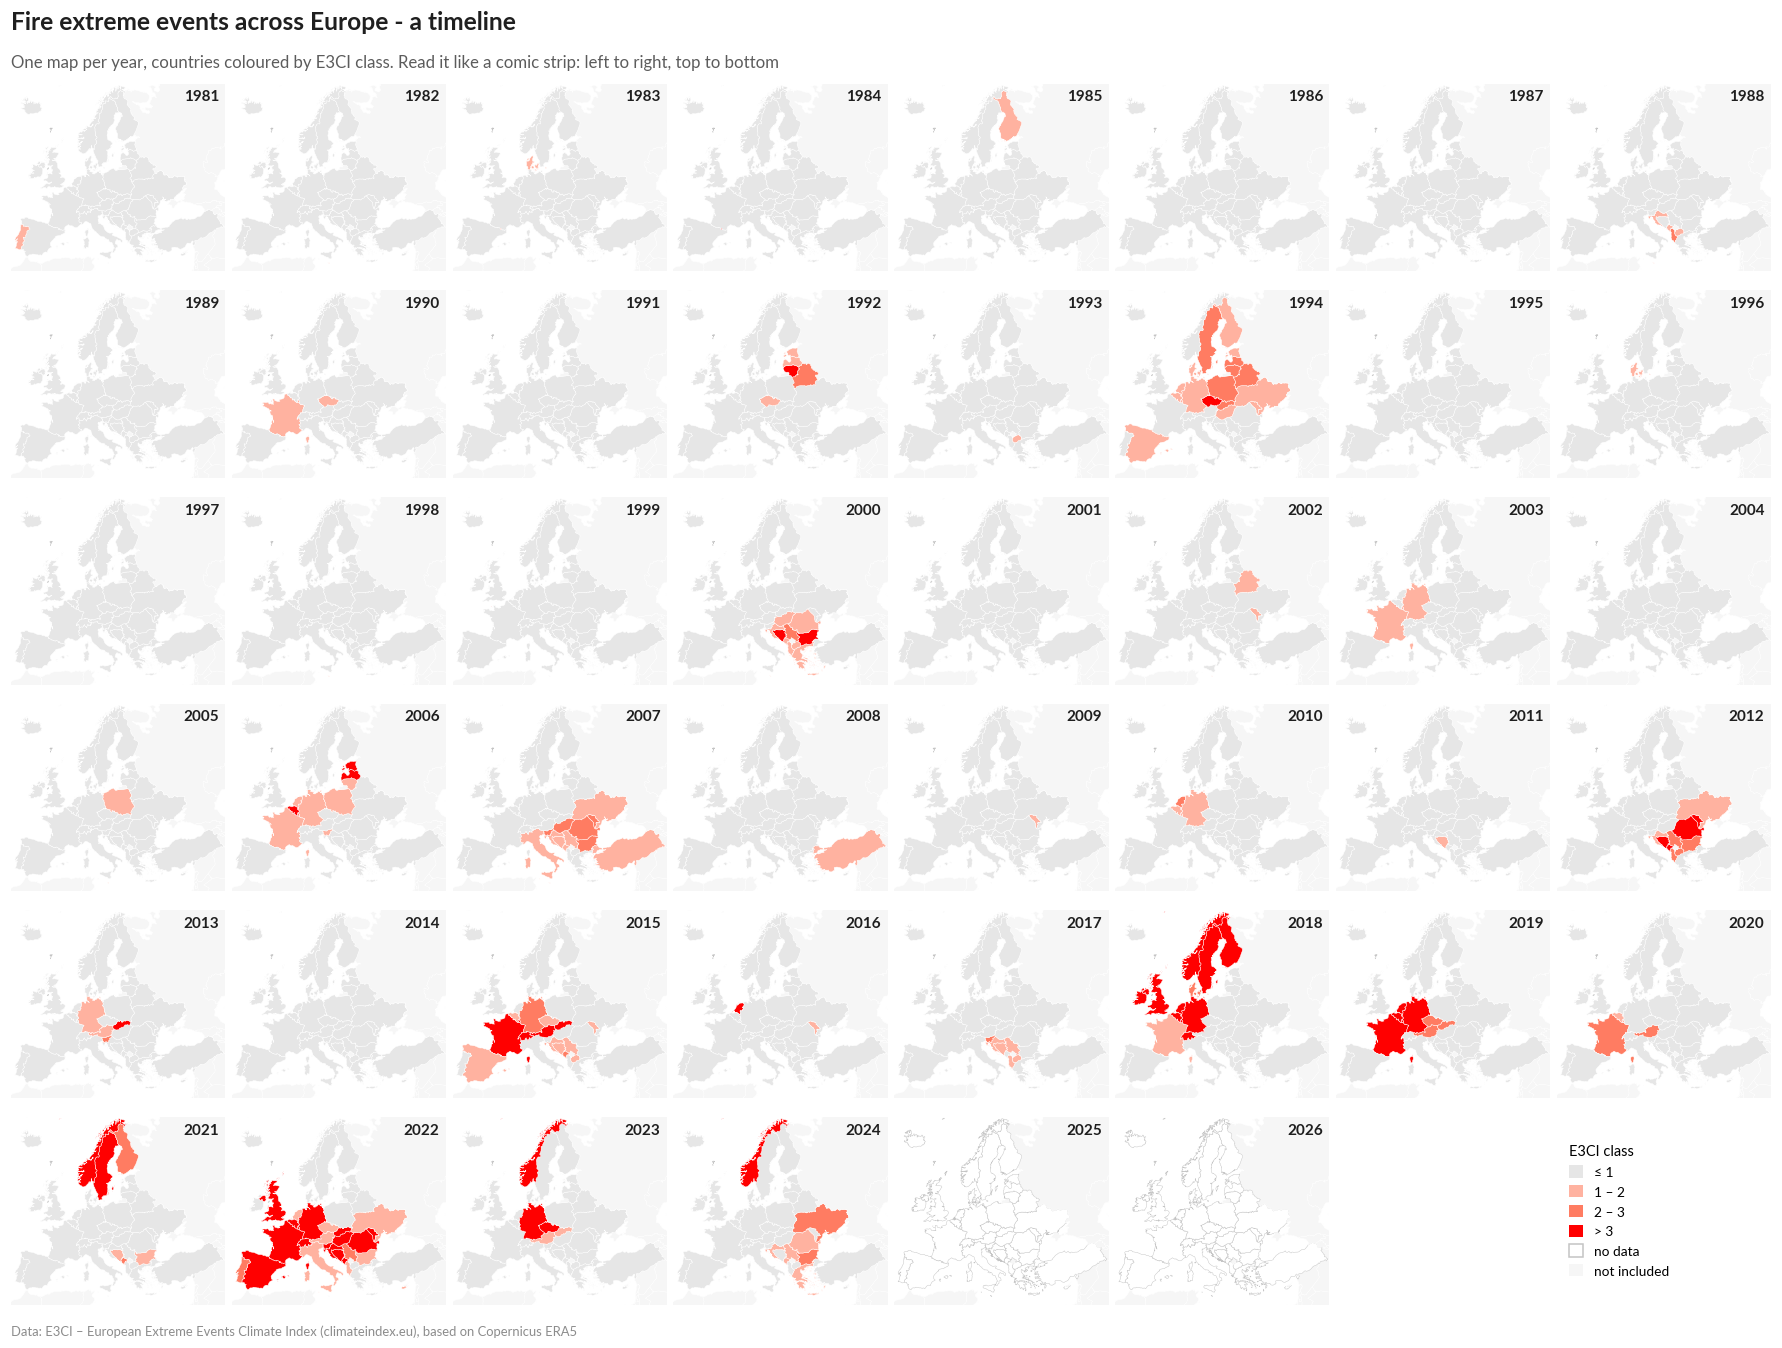

In [ ]:
# Settings of this chart
COMPONENT = "fire"
MONTH = 7
N_COLUMNS = 8
AREAS = EUROPE      # the coloured countries (the others stay light grey)
TITLE = "Fire extreme events across Europe - a timeline"   # your title between the quotes, or "" for the automatic title


def plot_map_grid(component, month=7, areas=EUROPE, n_columns=8, data=None, title=None, subtitle=None):
    dates = [pd.Timestamp(year, month, 1) for year in range(FIRST_YEAR, LAST_YEAR + 1)
             if pd.Timestamp(year, month, 1) <= LAST_DATE]
    n_rows = int(np.ceil((len(dates) + 1) / n_columns))
    fig, axes = plt.subplots(n_rows, n_columns, figsize=(2.0 * n_columns, 1.85 * n_rows),
                             gridspec_kw={"wspace": 0.03, "hspace": 0.1})
    fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
    axes = axes.ravel()
    for ax, date in zip(axes, dates):
        draw_map(ax, map_colors(component, date, areas, data))
        ax.text(0.97, 0.97, str(date.year), transform=ax.transAxes, ha="right", va="top",
                fontsize=10, fontweight="bold", color=INK)
    for ax in axes[len(dates):]:
        ax.set_axis_off()
    axes[-1].legend(handles=map_legend(component),
                    title="E3CI class", loc="center left", fontsize=9, title_fontsize=9.5,
                    handlelength=1, handleheight=1, alignment="left")
    add_titles(fig, title or f"{COMPONENTS[component]['label']} in {MONTH_NAMES[month - 1]}, every year since {FIRST_YEAR}",
               subtitle or "One map per year, countries coloured by E3CI class. "
                           "Read it like a comic strip: left to right, top to bottom")
    add_source(fig)
    save_figure(fig, "09_maps", component, MONTH_NAMES[month - 1])
    plt.show()


plot_map_grid(COMPONENT, MONTH, AREAS, N_COLUMNS, title=TITLE)


💬 **What do you see?** Compare the first rows with the last ones: in the 1980s an extreme July was a rare, local
event; since 2012 almost every July has hit large parts of Europe, some years in the north (2014, 2018, 2025),
others in the south and in the Balkans (2012, 2023, 2024).

---
## 3 · One country, zoom in: Italy ⏱ 12 min
After Europe as a whole, let's zoom in on one country: the charts below show **Italy** and **extreme heat** from
several angles, down to its regions. In the second part of the workshop you can choose your own country and
component.

In [ ]:
# The country and the component of the charts below
COUNTRY = "Netherlands"
COMPONENT = "extreme min T"

print(f"✔ Part 3 shows {COUNTRY} · {COMPONENTS[COMPONENT]['label']}")


✔ Part 3 shows Netherlands · Extreme min temperature


### 3.1 The barcode of extremes
Inspired by Ed Hawkins' *warming stripes*: one row per component, one cell per year.

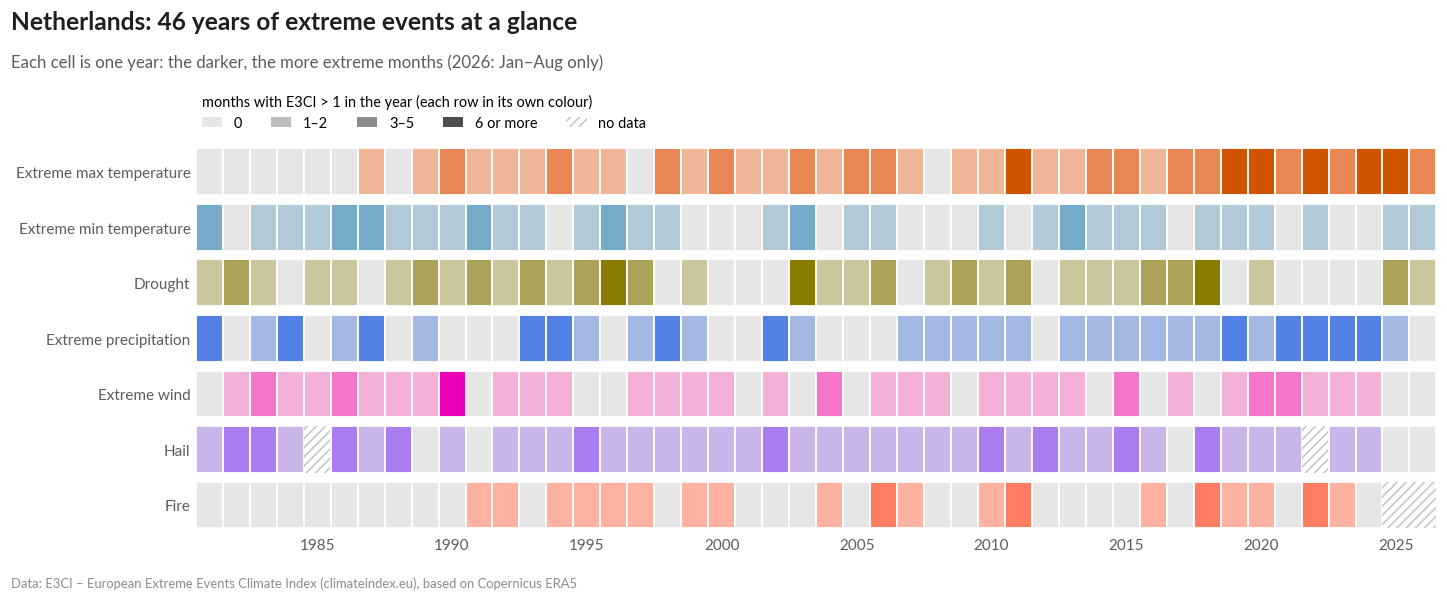

In [ ]:
# Uses the COUNTRY chosen at the top of Part 3. Other settings:
THRESHOLD = 1
TITLE = "Netherlands: 46 years of extreme events at a glance"   # your title between the quotes, or "" for the automatic title


def plot_barcode(country, threshold=1, data=None, title=None, subtitle=None):
    years = np.arange(FIRST_YEAR, LAST_YEAR + 1)
    bins = [(0, 0, "0"), (1, 2, "1–2"), (3, 5, "3–5"), (6, 12, "6 or more")]   # extreme months per year

    fig, ax = plt.subplots(figsize=(13, 4.3), layout="constrained")
    for row, component in enumerate(COMPONENT_ORDER):
        values = series(country, component, data)
        n_extreme = (values > threshold).groupby(values.index.year).sum().reindex(years)
        n_valid = values.notna().groupby(values.index.year).sum().reindex(years)
        for year in years:
            if n_valid[year] == 0:                                    # no data for this year
                ax.add_patch(plt.Rectangle((year - 0.5, row - 0.42), 1, 0.84, facecolor="white",
                                           edgecolor=AXIS, hatch="////", linewidth=0))
                continue
            for level, (low, high, label) in enumerate(bins):
                if low <= n_extreme[year] <= high:
                    color = COMPONENTS[component]["colors"][level]
            ax.add_patch(plt.Rectangle((year - 0.5, row - 0.42), 1, 0.84, facecolor=color,
                                       edgecolor="white", linewidth=1.2))

    ax.set_xlim(FIRST_YEAR - 0.5, LAST_YEAR + 0.5)
    ax.set_ylim(len(COMPONENT_ORDER) - 0.5, -0.5)
    ax.set_yticks(range(len(COMPONENT_ORDER)), [COMPONENTS[c]["label"] for c in COMPONENT_ORDER])
    ax.set_xticks(list(range(1985, LAST_YEAR + 1, 5)))
    ax.tick_params(length=0, labelsize=10)
    for side in ["left", "bottom"]:
        ax.spines[side].set_visible(False)

    greys = ["#E6E6E6", "#BDBDBD", "#8C8C8C", "#4D4D4D"]
    handles = [Patch(facecolor=g, label=b[2]) for g, b in zip(greys, bins)]
    handles.append(Patch(facecolor="white", edgecolor=AXIS, hatch="////", linewidth=0, label="no data"))
    ax.legend(handles=handles, title=f"months with E3CI > {threshold} in the year (each row in its own colour)",
              loc="lower left", bbox_to_anchor=(0, 1.02), ncol=5, fontsize=9.5, title_fontsize=9.5,
              alignment="left", handlelength=1.4, borderaxespad=0)
    partial = f" ({LAST_YEAR}: Jan–{LAST_DATE:%b} only)" if LAST_DATE.month < 12 else ""
    add_titles(fig, title or f"{country}: {LAST_YEAR - FIRST_YEAR + 1} years of extremes at a glance",
               subtitle or f"Each cell is one year: the darker, the more extreme months{partial}")
    add_source(fig)
    save_figure(fig, "03_barcode", country)
    plt.show()


plot_barcode(COUNTRY, THRESHOLD, title=TITLE)


### 3.2 Month by month, as in the Data Station
Now one component only: extreme heat. Every bar is one month, coloured by E3CI class; the dots mark the three most
intense months on record, with their value.

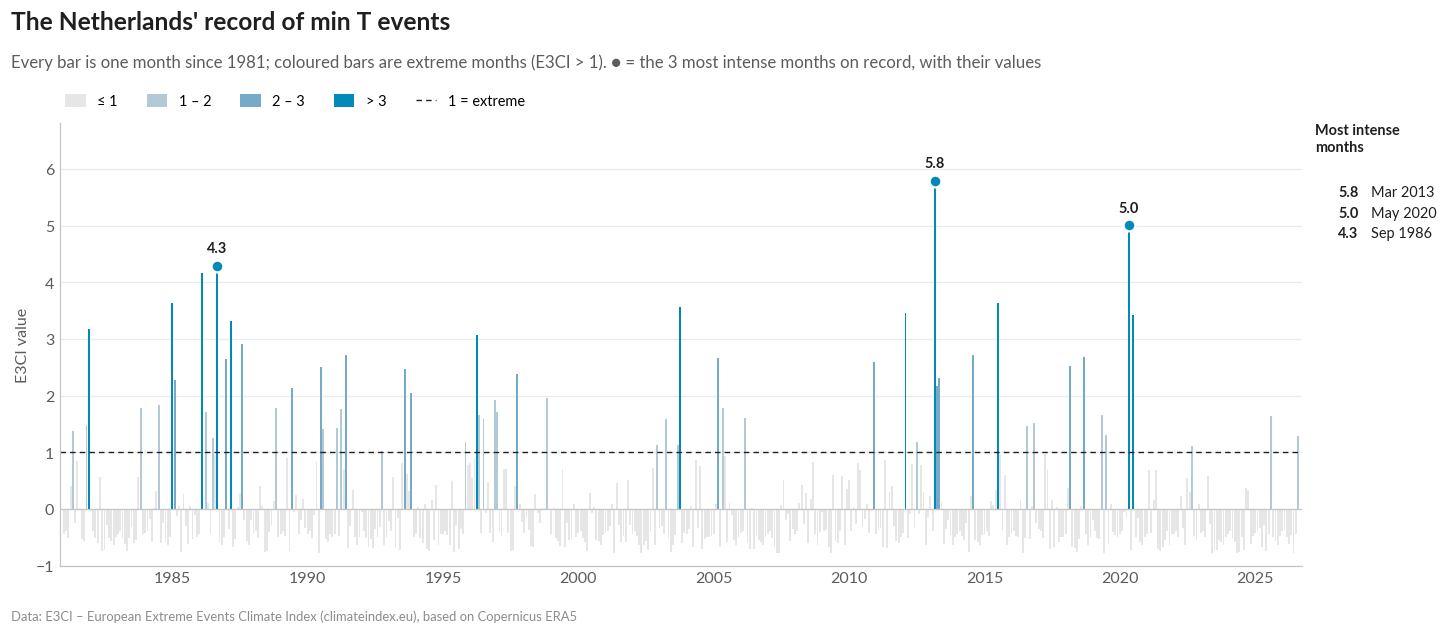

In [ ]:
# Uses the COUNTRY and COMPONENT chosen at the top of Part 3. Other settings:
TOP_N = 3
# Y_LIMIT: None = automatic (a few huge values could flatten all the others)
Y_LIMIT = None
TITLE = "The Netherlands' record of min T events"   # your title between the quotes, or "" for the automatic title

from matplotlib.transforms import Bbox


def covered(box, others):
    """How many pixels of the boxes `others` the box covers."""
    area = 0
    for other in others:
        overlap = Bbox.intersection(box, other)
        if overlap is not None:
            area += overlap.width * overlap.height
    return area


def write_values(ax, dots, texts, bars):
    """Write each text next to its dot, in the best of a few places around it: inside the chart and covering
    as little as possible of the bars, the dots and the texts already written (best of all: nothing)."""
    fig = ax.get_figure()
    fig.canvas.draw()                                  # the layout is ready: now the texts can be measured
    renderer = fig.canvas.get_renderer()
    chart = ax.get_window_extent(renderer)
    bar_boxes = [bar.get_window_extent(renderer) for bar in bars]
    radius = 5 * fig.dpi / 72                          # the size of a dot, in pixels
    taken = [Bbox.from_extents(x - radius, y - radius, x + radius, y + radius)       # the dots...
             for x, y in ax.transData.transform(dots.get_offsets())]                 # ... then the texts
    # The places to try, in order: (offset from the dot in points, alignment of the text)
    places = [((0, 7), "center"), ((7, 2), "left"), ((-7, 2), "right"), ((2, 7), "left"), ((-2, 7), "right"),
              ((0, 19), "center"), ((2, 19), "left"), ((-2, 19), "right")]
    for (x, y), text in zip(dots.get_offsets(), texts):
        best = None                                    # (score, label, box): the lower the score, the better
        for offset, ha in places:
            label = ax.annotate(text, (x, y), xytext=offset, textcoords="offset points", ha=ha, va="bottom",
                                fontsize=9.5, fontweight="bold", color=INK, zorder=6, in_layout=False)
            box = label.get_window_extent(renderer)
            outside = not (chart.x0 <= box.x0 and box.x1 <= chart.x1 and box.y1 <= chart.y1)
            score = 1e9 * outside + 5 * covered(box, taken) + covered(box, bar_boxes)
            if best is None or score < best[0]:
                if best is not None:
                    best[1].remove()
                best = (score, label, box)
            else:
                label.remove()
            if score == 0:                             # a free place: no need to look further
                break
        taken.append(best[2])


def plot_monthly_bars(area, component, top_n=3, y_limit=None, data=None, title=None, subtitle=None):
    values = series(area, component, data).dropna()
    if not has_data(values, area, component):
        return
    classes = e3ci_class(values.values)
    colors = [COMPONENTS[component]["colors"][int(c)] for c in classes]

    # Where to cut the axis: bars above y_top are cut and marked with ▲
    if y_limit is None:
        y_top = values.max() if values.max() <= 20 else 15
    else:
        y_top = y_limit
    cut = values > y_top

    fig, ax = plt.subplots(figsize=(13, 4.6), layout="constrained")
    bars = ax.bar(values.index, values.clip(upper=y_top), width=25, color=colors, edgecolor="none")
    ax.scatter(values.index[cut], [y_top] * int(cut.sum()), marker="^", s=18, color=INK_2, zorder=4)
    ax.axhline(0, color=AXIS, linewidth=0.8)
    ax.axhline(1, color=INK, linewidth=0.9, linestyle=(0, (4, 3)))

    # The top_n most intense months: a dot with its value on each one, and a list on the right
    top = values.nlargest(top_n)
    dots = ax.scatter(top.index, top.clip(upper=y_top), s=60, color=COMPONENTS[component]["color"],
                      edgecolor="white", linewidth=1.5, zorder=5)
    ax.text(1.01, 1.0, "Most intense\nmonths", transform=ax.transAxes, ha="left", va="top",
            fontsize=9.5, fontweight="bold", color=INK, linespacing=1.3)
    ax.text(1.045, 0.86, "\n".join(f"{value:.1f}" for value in top), transform=ax.transAxes, ha="right",
            va="top", multialignment="right", fontsize=9.5, fontweight="bold", color=INK, linespacing=1.6)
    ax.text(1.055, 0.86, "\n".join(f"{date:%b %Y}" for date in top.index), transform=ax.transAxes, ha="left",
            va="top", fontsize=9.5, color=INK, linespacing=1.6)

    y_bottom = min(-1.0, values.min() - 0.2)
    ax.set_ylim(y_bottom, y_top + 0.15 * (y_top - y_bottom))       # some room above the bars for the values
    ax.set_xlim(pd.Timestamp(FIRST_YEAR, 1, 1) - pd.Timedelta(days=60), LAST_DATE + pd.Timedelta(days=60))
    ax.set_ylabel("E3CI value")
    ax.grid(axis="y")
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    handles = class_legend(component)
    handles.append(Line2D([], [], color=INK, linewidth=0.9, linestyle=(0, (4, 3)), label="1 = extreme"))
    if cut.any():
        handles.append(Line2D([], [], marker="^", color=INK_2, linestyle="none", markersize=6,
                              label=f"bar cut: value above {y_top:g}"))
    ax.legend(handles=handles, loc="lower left", bbox_to_anchor=(0, 1.02), ncol=len(handles),
              fontsize=9.5, handlelength=1.4, handleheight=1, borderaxespad=0)

    # The value of each dot (e.g. 11.3), written where it covers neither the bars nor the other values
    write_values(ax, dots, [f"{value:.1f}" for value in top], bars)

    most = ("the most intense month on record, with its value" if top_n == 1
            else f"the {top_n} most intense months on record, with their values")
    add_titles(fig, title or f"{area} · {COMPONENTS[component]['label']}, month by month",
               subtitle or f"Every bar is one month since {FIRST_YEAR}; coloured bars are extreme months "
                           f"(E3CI > 1). ● = {most}")
    add_source(fig)
    save_figure(fig, "04_monthly_bars", area, component)
    plt.show()


plot_monthly_bars(COUNTRY, COMPONENT, TOP_N, Y_LIMIT, title=TITLE)


💬 The darkest bars, above 3, are almost all recent: 4 months in the 30 years 1981–2010, 30 since 2011. And the three
most intense months on record are October 2023, April 2024 and July 2026 (remember: an extreme October is an
unusually warm October, not a 40 °C day).

### 3.3 Records: are they falling faster than chance would predict?
The same months, seen through their **records**. A record is a month with a higher E3CI than every month before it
in the same country, since January 1981. In a climate that does not change, **records become rarer and rarer**:
after 10 years the chance that a month beats all the previous ones is about 1 in 120; after 40 years, about 1 in 480.
That's why we start counting in **1991**: in the first years almost every month is a record, because there is hardly
any history to beat.

📐 **How many records should we expect?** In a stable climate each of the first *n* months has the same chance of
being the highest, so month *n* sets a record with probability **1/n**. Adding up 1/n over the months since 1991 gives
the number of records we would expect if nothing were changing. It is a reference, not an exact forecast: anomalies
persist from one month to the next, so records can come in clusters.

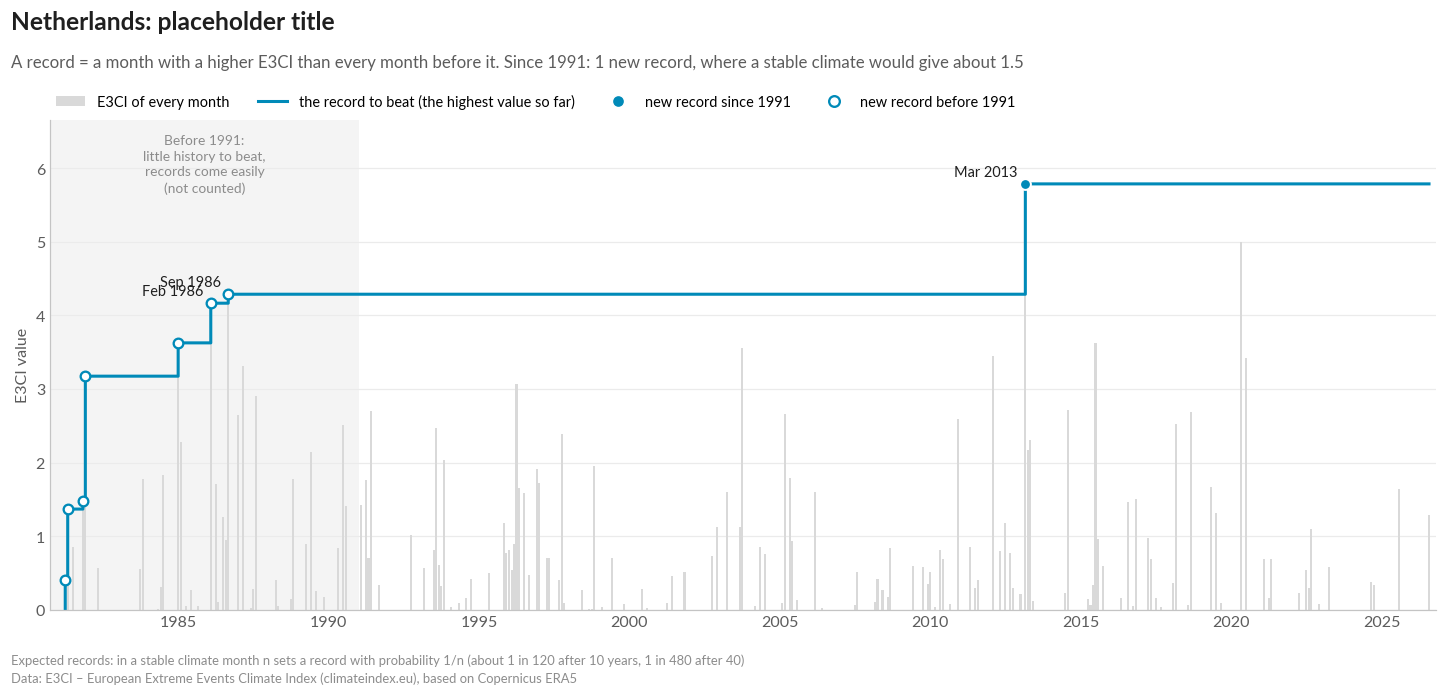

In [ ]:
# Uses the COUNTRY and COMPONENT chosen at the top of Part 3. Other settings:
START_YEAR = 1991      # records are counted from here: in the first years almost every month is a record
TITLE = "Netherlands: placeholder title"   # your title between the quotes, or "" for the automatic title


def find_records(values):
    """Months that beat every previous month (first month excluded) + the running maximum."""
    values = values.dropna()
    running_max = values.cummax()
    is_record = values > running_max.shift(1)
    if len(is_record) > 0:
        is_record.iloc[0] = False
    return is_record, running_max


def plot_records(area, component, start_year=1991, data=None, title=None, subtitle=None):
    values = series(area, component, data).dropna()
    if not has_data(values, area, component):
        return
    color = COMPONENTS[component]["color"]
    is_record, running_max = find_records(values)
    records = values[is_record]
    counted = records[records.index.year >= start_year]          # the records we count...
    early = records[records.index.year < start_year]             # ... and the "easy" ones of the first years

    # In a stable climate each of the first n months has the same chance of being the highest:
    # month n sets a record with probability 1/n. Added up since start_year = the records we would expect
    n_so_far = np.arange(1, len(values) + 1)
    expected = (1 / n_so_far)[values.index.year >= start_year].sum()
    observed = len(counted)

    fig, ax = plt.subplots(figsize=(13, 5), layout="constrained")
    start = pd.Timestamp(start_year, 1, 1)
    x_left = values.index[0] - pd.Timedelta(days=90)
    ax.axvspan(x_left, start, color="#F4F4F4", linewidth=0, zorder=0)       # the first years, not counted
    ax.bar(values.index, values.clip(lower=0), width=25, color="#D9D9D9")
    ax.step(running_max.index, running_max, where="post", color=color, linewidth=2)
    ax.scatter(early.index, early, s=40, facecolor="white", edgecolor=color, linewidth=1.5, zorder=3)
    ax.scatter(counted.index, counted, s=50, color=color, edgecolor="white", linewidth=1.3, zorder=3)
    for date, value in records.iloc[-3:].items():                            # label the last 3 records
        ax.annotate(f"{date:%b %Y}", (date, value), xytext=(-5, 5), textcoords="offset points",
                    ha="right", fontsize=9.5, color=INK)
    y_top = values.max() * 1.15
    ax.text(x_left + (start - x_left) / 2, y_top * 0.97,
            f"Before {start_year}:\nlittle history to beat,\nrecords come easily\n(not counted)",
            ha="center", va="top", fontsize=9, color=INK_3, linespacing=1.35)
    ax.set_xlim(x_left, LAST_DATE + pd.Timedelta(days=90))
    ax.set_ylim(0, y_top)
    ax.set_ylabel("E3CI value")
    ax.grid(axis="y")
    ax.set_axisbelow(True)
    ax.tick_params(length=0)

    handles = [Patch(facecolor="#D9D9D9", label="E3CI of every month"),
               Line2D([], [], color=color, linewidth=2, label="the record to beat (the highest value so far)"),
               Line2D([], [], marker="o", linestyle="none", color=color, markeredgecolor="white", markersize=8,
                      label=f"new record since {start_year}"),
               Line2D([], [], marker="o", linestyle="none", markerfacecolor="white", markeredgecolor=color,
                      markeredgewidth=1.5, markersize=7, label=f"new record before {start_year}")]
    ax.legend(handles=handles, loc="lower left", bbox_to_anchor=(0, 1.01), ncol=4, fontsize=9.5, borderaxespad=0)

    # A title written by the data: observed vs expected records since start_year
    label = COMPONENTS[component]["label"]
    ratio = observed / expected if expected > 0 else np.nan
    if np.isnan(ratio):
        headline = f"{area} · {label}: not enough data to count records"
    elif ratio >= 1.5:
        times = f"{ratio:.0f}" if ratio >= 3 else f"{ratio:.1f}"
        headline = f"{area} · {label}: records fall {times}× more often than in a stable climate"
    elif ratio <= 0.67:
        headline = f"{area} · {label}: fewer new records than in a stable climate"
    else:
        headline = f"{area} · {label}: about as many records as in a stable climate"
    n_records = "1 new record" if observed == 1 else f"{observed} new records"
    add_titles(fig, title or headline,
               subtitle or f"A record = a month with a higher E3CI than every month before it. Since {start_year}: "
                           f"{n_records}, where a stable climate would give about {expected:.1f}")
    add_source(fig, f"Expected records: in a stable climate month n sets a record with probability 1/n "
                    f"(about 1 in 120 after 10 years, 1 in 480 after 40)")
    save_figure(fig, "12_records", area, component)
    plt.show()


plot_records(COUNTRY, COMPONENT, START_YEAR, title=TITLE)


💬 Since 1991 Italy has set **6 records** of extreme heat, where a stable climate would give about 1.5, and 3 of them
in the last ten years alone (April 2018, October 2022, October 2023), when about 0.2 would be expected. Every step of
the staircase raises the bar, and yet the bar keeps being beaten.

### 3.4 Which months, which years?
The same data as a heatmap: rows are months, columns are years. Top: extreme months per year.
Right: how often each calendar month was extreme, then (grey) and now (colour).

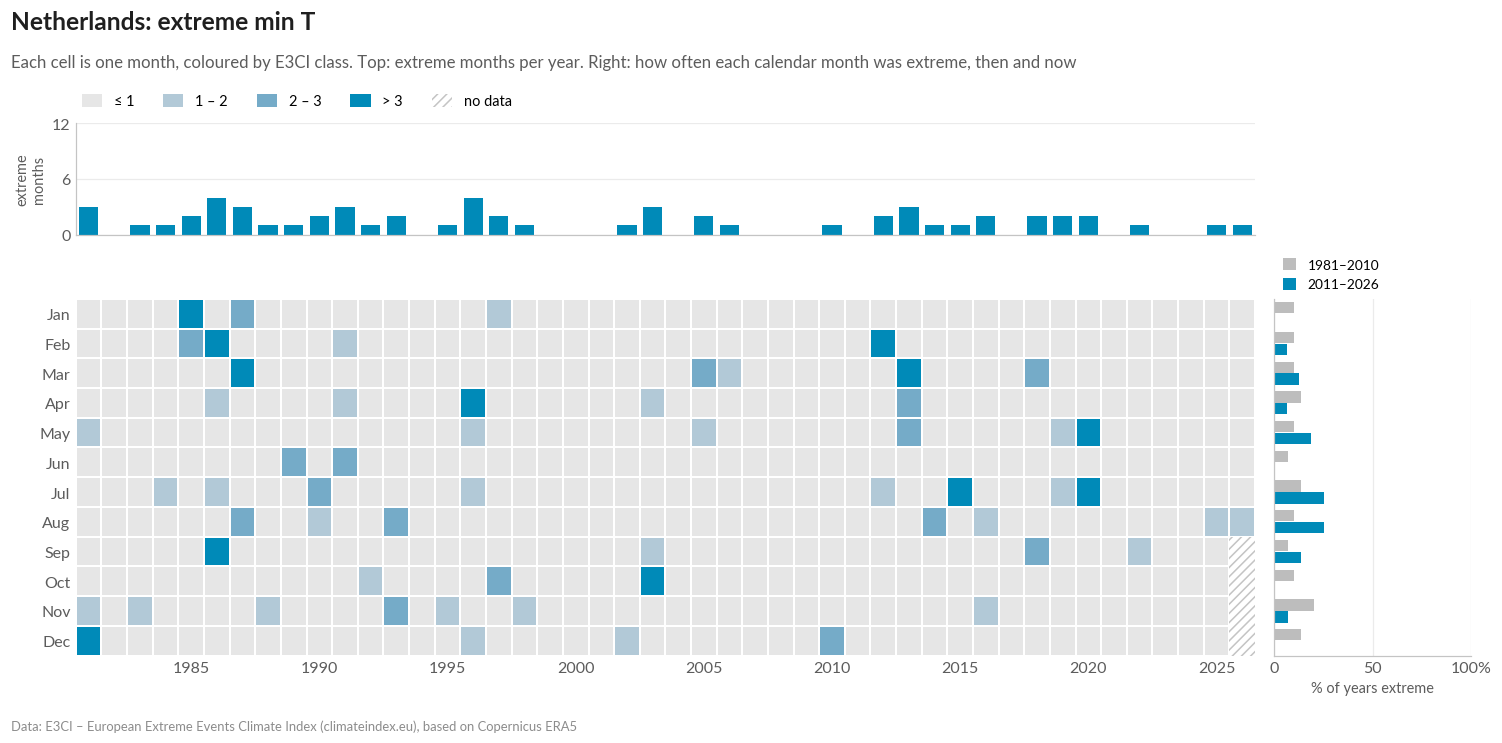

In [ ]:
# Uses the COUNTRY and COMPONENT chosen at the top of Part 3. Other settings:
TITLE = "Netherlands: extreme min T"   # your title between the quotes, or "" for the automatic title


def plot_month_year_heatmap(area, component, data=None, title=None, subtitle=None):
    years = np.arange(FIRST_YEAR, LAST_YEAR + 1)
    values = series(area, component, data)
    if not has_data(values, area, component):
        return

    # A grid of 12 months x N years
    grid = np.full((12, len(years)), np.nan)
    for date, value in values.items():
        grid[date.month - 1, date.year - FIRST_YEAR] = value
    classes = e3ci_class(grid)
    cmap, norm = class_cmap(component)
    color = COMPONENTS[component]["color"]

    fig = plt.figure(figsize=(13.5, 5.6), layout="constrained")
    gs = fig.add_gridspec(2, 2, width_ratios=[6, 1], height_ratios=[1, 3.2])
    ax_top = fig.add_subplot(gs[0, 0])
    ax = fig.add_subplot(gs[1, 0], sharex=ax_top)
    ax_right = fig.add_subplot(gs[1, 1], sharey=ax)

    # 1. The heatmap (white lines between cells)
    ax.pcolormesh(years, np.arange(12), classes, cmap=cmap, norm=norm, edgecolors="white", linewidth=1.2)
    hatch_missing(ax, years, np.arange(12), grid)
    ax.set_yticks(range(12), MONTH_ABBR)
    ax.set_ylim(11.5, -0.5)
    ax.set_xticks(list(range(1985, LAST_YEAR + 1, 5)))
    ax.tick_params(length=0)
    for side in ["left", "bottom"]:
        ax.spines[side].set_visible(False)

    # 2. Top: how many extreme months in each year
    n_per_year = (grid > 1).sum(axis=0)
    ax_top.bar(years, n_per_year, width=0.75, color=color)
    ax_top.set_ylabel("extreme\nmonths", fontsize=9.5)
    ax_top.set_ylim(0, 12)
    ax_top.set_yticks([0, 6, 12])
    ax_top.grid(axis="y")
    ax_top.set_axisbelow(True)
    ax_top.tick_params(length=0, labelbottom=False)

    # 3. Right: how often was each calendar month extreme, then vs now (% of years)
    base_cols = (years >= BASELINE[0]) & (years <= BASELINE[1])
    recent_cols = (years >= RECENT[0]) & (years <= RECENT[1])
    for rows_period, offset, bar_color, label in [(base_cols, -0.2, "#BDBDBD", f"{BASELINE[0]}–{BASELINE[1]}"),
                                                  (recent_cols, 0.2, color, f"{RECENT[0]}–{RECENT[1]}")]:
        sub = grid[:, rows_period]
        pct = 100 * (sub > 1).sum(axis=1) / np.maximum((~np.isnan(sub)).sum(axis=1), 1)
        ax_right.barh(np.arange(12) + offset, pct, height=0.38, color=bar_color, label=label)
    ax_right.set_xlim(0, 100)
    ax_right.set_xticks([0, 50, 100], ["0", "50", "100%"])
    ax_right.set_xlabel("% of years extreme", fontsize=9.5)
    ax_right.tick_params(length=0, labelleft=False)
    ax_right.grid(axis="x")
    ax_right.set_axisbelow(True)
    ax_right.legend(loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=9, handlelength=1,
                    handleheight=1, borderaxespad=0.2)

    ax_top.legend(handles=class_legend(component) + [no_data_patch()], loc="lower left",
                  bbox_to_anchor=(0, 1.08), ncol=5, fontsize=9.5, handlelength=1.4, handleheight=1, borderaxespad=0)
    add_titles(fig, title or f"{area} · {COMPONENTS[component]['label']}: which months, which years?",
               subtitle or "Each cell is one month, coloured by E3CI class. Top: extreme months per year. "
                           "Right: how often each calendar month was extreme, then and now")
    add_source(fig)
    save_figure(fig, "05_heatmap_month_year", area, component)
    plt.show()


plot_month_year_heatmap(COUNTRY, COMPONENT, title=TITLE)


### 3.5 A real event: the Emilia-Romagna floods, May 2023
Many events hit only one region: here we use the **regional data** loaded in the setup. In May 2023 two waves of
torrential rain flooded Romagna: was it the most intense month on record in Emilia-Romagna? How does it compare with
the rest of Europe? The first cell lists other famous events: in the second part of the workshop you can choose one
of them.

In [ ]:
# @title 📚 The case studies
CASE_STUDIES = {
    "Emilia-Romagna floods, May 2023": {
        "area": "Emilia-romagna", "component": "extreme prec", "date": "2023-05", "level": "regional",
        "story": "Two waves of torrential rain (2–3 and 16–17 May) made 23 rivers overflow; 17 people died."},
    "Storm Daniel, Thessaly (Greece), September 2023": {
        "area": "Thessalia", "component": "extreme prec", "date": "2023-09", "level": "regional",
        "story": "From 4 September, days of rain flooded the Thessaly plain: Greece's costliest storm on record."},
    "Floods in Germany and Belgium, July 2021": {
        "area": "Nordrhein-Westfalen", "component": "extreme prec", "date": "2021-07", "level": "regional",
        "story": "On 14–15 July extreme rain caused flash floods in the Ahr, Erft and Vesdre valleys: more than 200 deaths."},
    "Storm Boris, Central Europe, September 2024": {
        "area": "Niederosterreich", "component": "extreme prec", "date": "2024-09", "level": "regional",
        "story": "In mid-September days of rain flooded Austria, Czechia, Poland and Romania."},
    "Storm Vaia, Veneto (Italy), October 2018": {
        "area": "Veneto", "component": "extreme wind", "date": "2018-10", "level": "regional",
        "story": "At the end of October violent winds flattened millions of trees in the forests of the Dolomites."},
    "Storm Ciarán, Brittany (France), November 2023": {
        "area": "Bretagne", "component": "extreme wind", "date": "2023-11", "level": "regional",
        "story": "On 1–2 November hurricane-force gusts hit Brittany; over a million French homes lost power."},
    "Giant hail in northern Italy, July 2023": {
        "area": "Lombardia", "component": "hail", "date": "2023-07", "level": "regional",
        "story": "A week of violent hailstorms from Lombardy to Friuli, where a 19 cm hailstone fell on 24 July: a European record."},
    "Sicily heatwave, July 2023": {
        "area": "Sicilia", "component": "extreme max T", "date": "2023-07", "level": "regional",
        "story": "A long heatwave in the second half of July; wildfires around Palermo even closed its airport."},
    "Andalusia drought, April 2023": {
        "area": "Andalucia", "component": "drought", "date": "2023-04", "level": "regional",
        "story": "A record April heatwave on top of a long drought dried out southern Spain."},
    "Portugal wildfires, October 2017": {
        "area": "Coimbra", "component": "fire", "date": "2017-10", "level": "regional",
        "story": "On 15 October, fanned by the winds of hurricane Ophelia, hundreds of fires burned central Portugal."},
    "Latest month in the data": {
        "area": "Italy", "component": "extreme max T", "date": f"{LAST_DATE:%Y-%m}", "level": "national",
        "story": "The most recent month in this file: how does it compare with the past?"},
}
print("Available case studies:")
for name in CASE_STUDIES:
    print("  •", name)


Available case studies:
  • Emilia-Romagna floods, May 2023
  • Storm Daniel, Thessaly (Greece), September 2023
  • Floods in Germany and Belgium, July 2021
  • Storm Boris, Central Europe, September 2024
  • Storm Vaia, Veneto (Italy), October 2018
  • Storm Ciarán, Brittany (France), November 2023
  • Giant hail in northern Italy, July 2023
  • Sicily heatwave, July 2023
  • Andalusia drought, April 2023
  • Portugal wildfires, October 2017
  • Latest month in the data


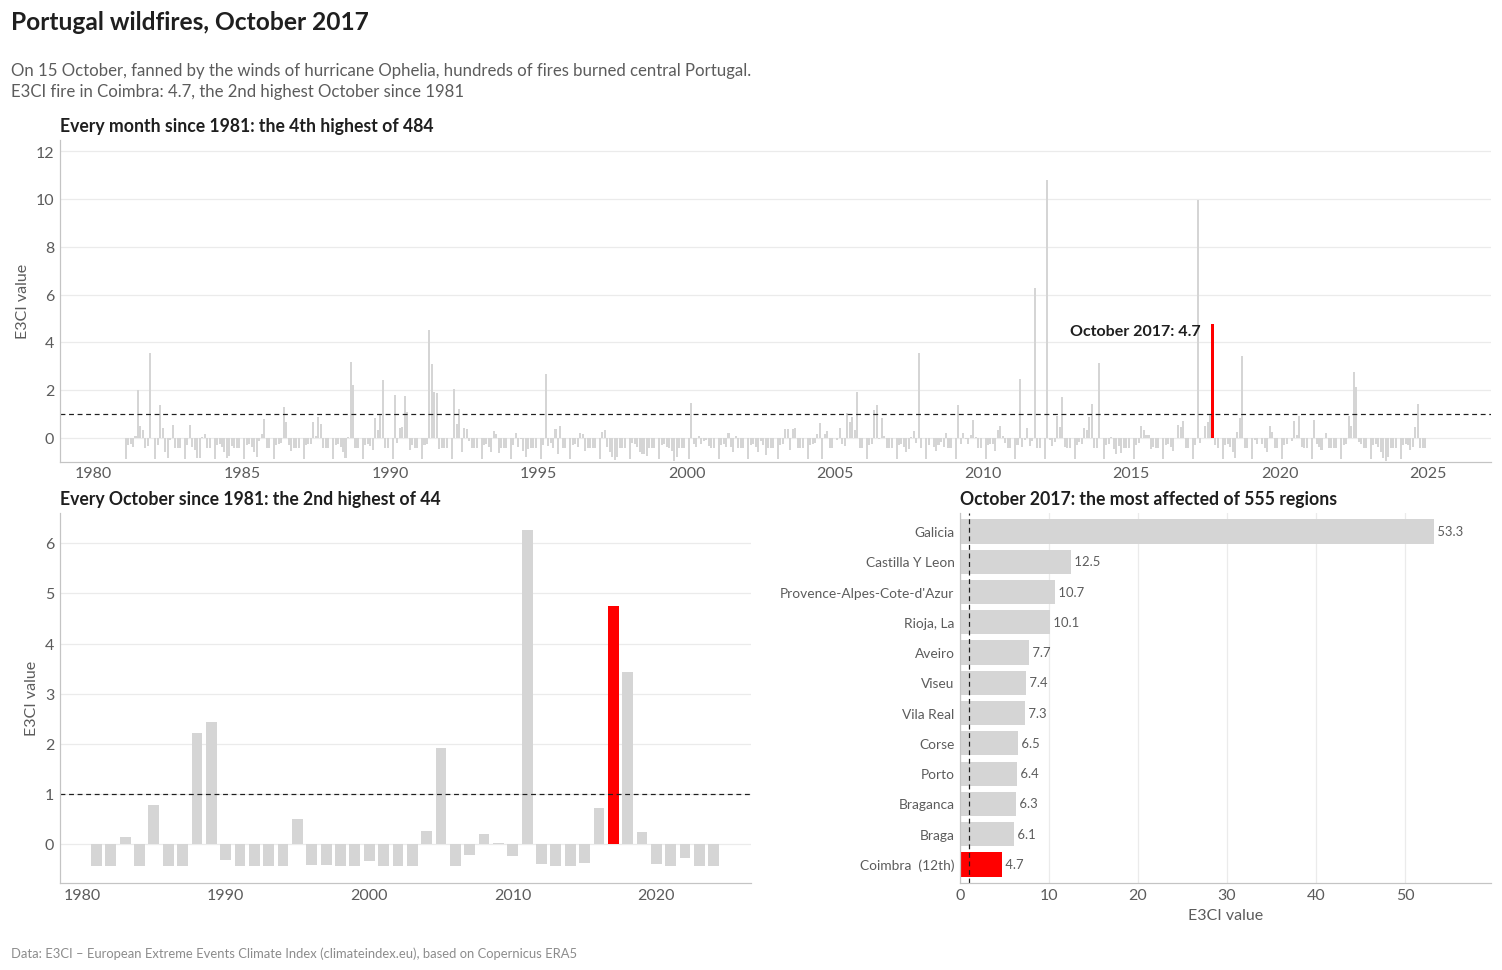

In [ ]:
# Settings of this chart
CASE = "Portugal wildfires, October 2017"     # one of the case studies listed by the cell above
TITLE = ""   # your title between the quotes, or "" for the automatic title


def ordinal(n):
    return f"{n}{'th' if 10 <= n % 100 <= 20 else {1: 'st', 2: 'nd', 3: 'rd'}.get(n % 10, 'th')}"


def the_nth_highest(n):
    return "the highest" if n == 1 else f"the {ordinal(n)} highest"


def plot_event(area, component, date, level="national", title=None, story="", data=None, subtitle=None):
    if data is not None:                                  # data=regional works as well as level="regional"
        level = "national" if data is national else "regional"
    if level == "regional" and "regional" not in globals():
        raise RuntimeError("Load the regional data first: run the cell '⚙️ Setup 5/5 · Regional data' at the top.")
    if level == "regional" and area in COUNTRIES and area not in REGIONS:
        raise ValueError(f"'{area}' is a country: use level=\"national\".")
    if level != "regional" and area not in COUNTRIES and area in globals().get("REGIONS", []):
        raise ValueError(f"'{area}' is a region: use level=\"regional\".")
    data = regional if level == "regional" else national
    date = pd.Timestamp(date).to_period("M").to_timestamp()      # "2024-10-19" -> October 2024
    values = series(area, component, data).dropna()
    if not has_data(values, area, component):
        return
    if date not in values.index:
        raise ValueError(f"No {component} data for {area} in {date:%B %Y} "
                         f"(the data go from {values.index[0]:%B %Y} to {values.index[-1]:%B %Y}).")
    value = values[date]
    same_month = values[values.index.month == date.month]
    rank_all = int((values > value).sum()) + 1
    rank_month = int((same_month > value).sum()) + 1
    color = COMPONENTS[component]["color"]
    grey = "#D5D5D5"

    fig = plt.figure(figsize=(13.5, 7.4), layout="constrained")
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.15], width_ratios=[1.3, 1])
    ax_all = fig.add_subplot(gs[0, :])
    ax_month = fig.add_subplot(gs[1, 0])
    ax_europe = fig.add_subplot(gs[1, 1])

    # 1. The whole history, the event in colour
    y_top = min(values.max(), max(15, value)) * 1.1
    ax_all.bar(values.index, values.clip(upper=y_top), width=25, color=grey)
    ax_all.bar([date], [min(value, y_top)], width=40, color=color)
    ax_all.annotate(f"{date:%B %Y}: {value:.1f}", (date, min(value, y_top)), xytext=(-8, 0),
                    textcoords="offset points", ha="right", va="top", fontsize=10.5, fontweight="bold", color=INK)
    ax_all.axhline(1, color=INK, linewidth=0.8, linestyle=(0, (4, 3)))
    ax_all.set_ylim(min(-1, values.min()), y_top * 1.05)
    ax_all.set_title(f"Every month since {values.index[0].year}: {the_nth_highest(rank_all)} of {len(values)}")
    ax_all.set_ylabel("E3CI value")

    # 2. The same calendar month, year after year
    ax_month.bar(same_month.index.year, same_month.clip(upper=y_top), width=0.75,
                 color=[color if d == date else grey for d in same_month.index])
    ax_month.axhline(1, color=INK, linewidth=0.8, linestyle=(0, (4, 3)))
    ax_month.set_title(f"Every {MONTH_NAMES[date.month - 1]} since {same_month.index[0].year}: "
                       f"{the_nth_highest(rank_month)} of {len(same_month)}")
    ax_month.set_ylabel("E3CI value")

    # 3. Europe in the same month: the most affected areas
    areas = EUROPE_REGIONS if level == "regional" else EUROPE
    if area not in areas:                                 # a place outside Europe: compare it too
        areas = areas + [area]
    europe = table(component, areas, data).loc[date].dropna().sort_values(ascending=False)
    top = europe.head(12)
    if area not in top.index:
        top = pd.concat([top.head(11), europe[[area]]])
    labels = [f"{name}  ({ordinal(int((europe > v).sum()) + 1)})" if name == area else name for name, v in top.items()]
    ax_europe.barh(range(len(top)), top, color=[color if n == area else grey for n in top.index])
    for i, v in enumerate(top):
        ax_europe.text(v, i, f" {v:.1f}", va="center", fontsize=8.5, color=INK_2)
    ax_europe.set_xlim(0, top.max() * 1.12)
    ax_europe.set_yticks(range(len(top)), labels, fontsize=9)
    ax_europe.set_ylim(len(top) - 0.4, -0.6)
    ax_europe.axvline(1, color=INK, linewidth=0.8, linestyle=(0, (4, 3)))
    ax_europe.set_title(f"{date:%B %Y}: the most affected of {len(europe)} {'regions' if level == 'regional' else 'countries'}")
    ax_europe.set_xlabel("E3CI value")

    for ax in [ax_all, ax_month, ax_europe]:
        ax.grid(axis="x" if ax is ax_europe else "y")
        ax.set_axisbelow(True)
        ax.tick_params(length=0)
    facts = (f"E3CI {COMPONENTS[component]['label'].lower()} in {area}: {value:.1f}, "
             f"{the_nth_highest(rank_month)} {MONTH_NAMES[date.month - 1]} since {values.index[0].year}")
    add_titles(fig, title or f"{area} · {COMPONENTS[component]['label']} · {date:%B %Y}",
               subtitle or (f"{story}\n{facts}" if story else facts))
    add_source(fig)
    save_figure(fig, "13_case", area, component, f"{date:%Y-%m}")
    plt.show()


def plot_case_study(name, title=None):
    case = CASE_STUDIES[name]
    plot_event(case["area"], case["component"], case["date"], case["level"], title=title or name, story=case["story"])


plot_case_study(CASE, title=TITLE)


---
## ✅ End of the guided tour
In the second part of the workshop you will work on a copy of this notebook, connected to the
[Climate Gazette](https://gazette.climateindex.eu/): choose the charts that tell your story, change the country, the
component or the month in the settings at the top of each cell, give each chart a title that states the finding
(write it in `TITLE`, at the top of the cell), and add your text.

🔎 **Want to go further?** Below there are three **extra charts** about Italy and its regions to explore on your own.

---
## ⭐ Extra charts: explore them on your own
More charts for those who want to go further. They work like the ones above: run them from top to bottom.

### E.1 What changed?
All seven components for one country: the share of extreme months in 1981–2010 (grey) and 2011–2026 (colour).
The title is written **by the data**: it names the component that increased the most.

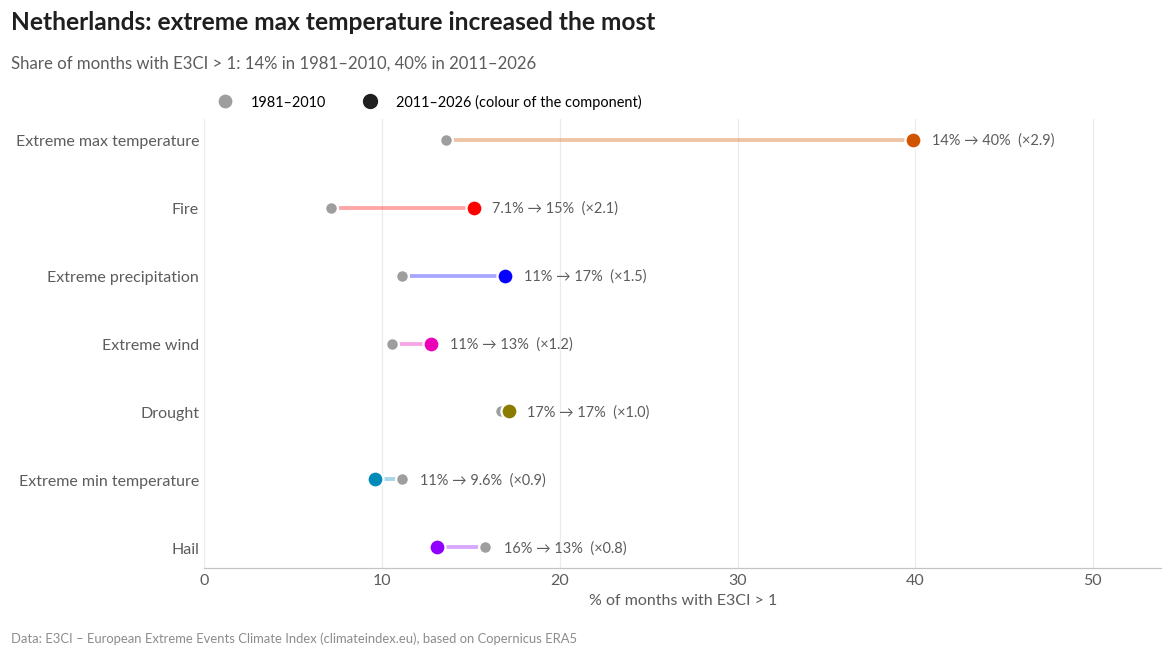

In [ ]:
# Uses the COUNTRY chosen at the top of Part 3. Other settings:
THRESHOLD = 1
TITLE = ""   # your title between the quotes, or "" for the automatic title


def plot_what_changed(area, threshold=1, data=None, title=None, subtitle=None):
    rows = []
    for component in COMPONENT_ORDER:
        values = series(area, component, data)
        then = values[in_period(values.index, BASELINE)].dropna()
        now = values[in_period(values.index, RECENT)].dropna()
        rows.append({"component": component,
                     "then": 100 * (then > threshold).mean(),
                     "now": 100 * (now > threshold).mean()})
    result = pd.DataFrame(rows).dropna()                             # components without data are left out
    result["change"] = result["now"] - result["then"]
    result = result.sort_values("change").reset_index(drop=True)      # biggest increase on top

    fig, ax = plt.subplots(figsize=(10.5, 4.8), layout="constrained")
    for y, row in result.iterrows():
        color = COMPONENTS[row["component"]]["color"]
        ax.plot([row["then"], row["now"]], [y, y], color=color, linewidth=2.5, alpha=0.35,
                solid_capstyle="round", zorder=1)
        ax.scatter(row["then"], y, s=70, color="#9E9E9E", edgecolor="white", linewidth=1.5, zorder=3)
        ax.scatter(row["now"], y, s=110, color=color, edgecolor="white", linewidth=1.5, zorder=3)
        ax.annotate(format_change(row["then"], row["now"]), (max(row["then"], row["now"]), y),
                    xytext=(12, 0), textcoords="offset points", va="center", fontsize=9.5, color=INK_2)

    ax.set_yticks(range(len(result)), [COMPONENTS[c]["label"] for c in result["component"]])
    ax.set_xlim(0, max(10, np.nanmax(result[["then", "now"]].values) * 1.35))
    ax.set_xlabel(f"% of months with E3CI > {threshold}")
    ax.grid(axis="x")
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    ax.spines["left"].set_visible(False)
    handles = [Line2D([], [], marker="o", color="#9E9E9E", linestyle="none", markersize=8,
                      label=f"{BASELINE[0]}–{BASELINE[1]}"),
               Line2D([], [], marker="o", color=INK, linestyle="none", markersize=9,
                      label=f"{RECENT[0]}–{RECENT[1]} (colour of the component)")]
    ax.legend(handles=handles, loc="lower left", bbox_to_anchor=(0, 1.01), ncol=2, fontsize=9.5,
              borderaxespad=0)

    top = result.iloc[-1]                                  # the component that increased the most
    if top["change"] > 0:
        headline = f"{area}: {COMPONENTS[top['component']]['label'].lower()} increased the most"
    else:
        headline = f"{area}: no component became more frequent"
    add_titles(fig, title or headline,
               subtitle or f"Share of months with E3CI > {threshold}: {format_pct(top['then'])} in "
                           f"{BASELINE[0]}–{BASELINE[1]}, {format_pct(top['now'])} in {RECENT[0]}–{RECENT[1]}")
    add_source(fig)
    save_figure(fig, "06_what_changed", area, f"threshold{threshold}")
    plt.show()


plot_what_changed(COUNTRY, THRESHOLD, title=TITLE)


### E.2 Heat vs cold, region by region
In Italy as a whole heat extremes grow and cold extremes fade (see the barcode in Part 3): is it the same in every
region? Here we use the **regional data** loaded in the setup. Each dot is a month above 2 in one of the 20 Italian
regions: orange = heat extremes, blue = cold extremes; the bigger dots are above 3. The title is generated by the code
from the first and the last ten years.

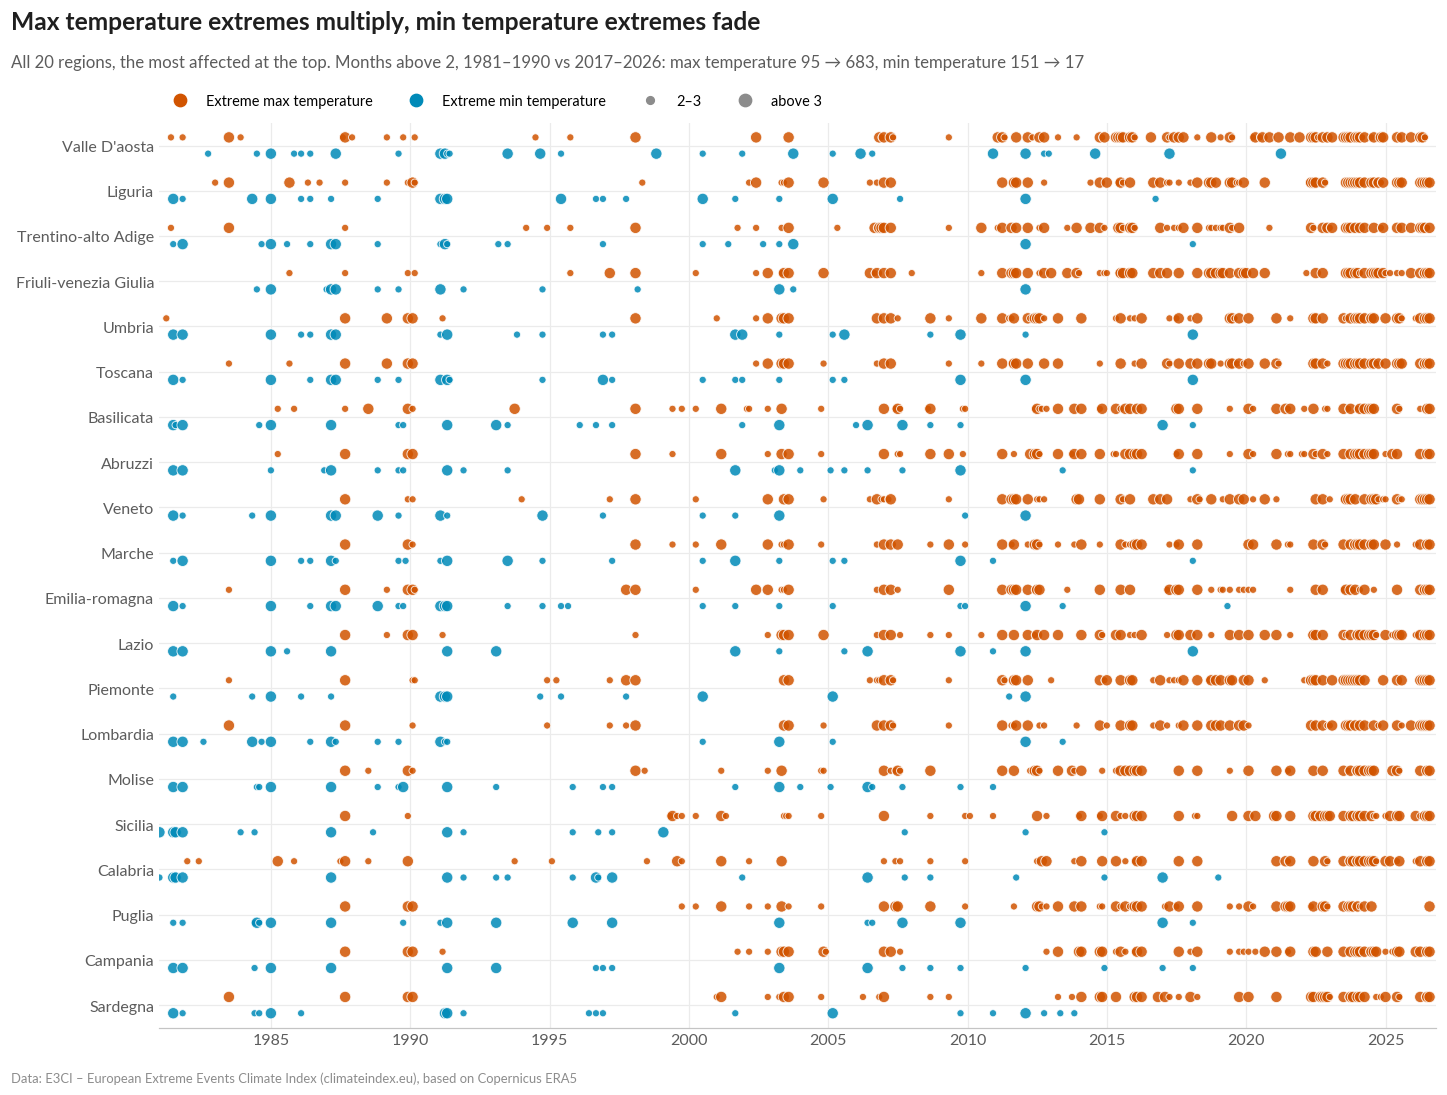

In [ ]:
# Settings of this chart
THRESHOLD = 2
TOP_N = 20
# the components to compare (two or more) and the areas to look at
COMPARE = ["extreme max T", "extreme min T"]
AREAS = ITALIAN_REGIONS      # the 20 Italian regions, or countries (e.g. EUROPE)
TITLE = ""   # your title between the quotes, or "" for the automatic title


def plot_timeline(components, threshold=2, top_n=20, areas=None, data=None, title=None, subtitle=None):
    if isinstance(components, str):                  # one component is fine too
        components = [components]
    areas = default_areas(areas, data)
    data = data_for(areas) if data is None else data      # countries or regions? the names decide
    kind = "countries" if data is None or data is national else "regions"

    # 1. Count the events of each country to find the most affected ones
    totals = pd.Series(0, index=areas)
    for component in components:
        totals = totals + (table(component, areas, data) > threshold).sum()
    countries = totals.sort_values(ascending=False).index[:top_n].tolist()

    fig, ax = plt.subplots(figsize=(13, 1.6 + 0.36 * len(countries)), layout="constrained")
    offsets = np.linspace(-0.18, 0.18, len(components))
    counts, verbs = [], []
    for component, offset in zip(components, offsets):
        values = table(component, countries, data)
        first = values.loc[:f"{FIRST_YEAR + 9}"]                 # the first 10 years
        last = values.loc[f"{LAST_YEAR - 9}":]                  # the last 10 years
        n_first, n_last = int((first > threshold).sum().sum()), int((last > threshold).sum().sum())
        counts.append(f"{COMPONENTS[component]['short'].lower()} {n_first} → {n_last}")
        # compare RATES (events per month with data), because some months have no data
        rate_first = n_first / max(first.notna().sum().sum(), 1)
        rate_last = n_last / max(last.notna().sum().sum(), 1)
        change = rate_last / rate_first if rate_first > 0 else np.inf
        if n_first + n_last < 10:
            verb = "are rare"
        elif change >= 2:
            verb = "multiply"
        elif change >= 1.2:
            verb = "increase"
        elif change <= 0.8:
            verb = "fade"
        else:
            verb = "hold steady"
        verbs.append(f"{COMPONENTS[component]['short'].lower()} extremes {verb}")
        for row, country in enumerate(countries):
            events = values[country][values[country] > threshold]
            sizes = [22 if v <= 3 else 55 for v in events.values]        # bigger dot = E3CI above 3
            ax.scatter(events.index, [row + offset] * len(events), s=sizes,
                       color=COMPONENTS[component]["color"], alpha=0.85, edgecolor="white", linewidth=0.6)

    ax.set_yticks(range(len(countries)), countries)
    ax.set_ylim(len(countries) - 0.5, -0.5)
    ax.set_xlim(pd.Timestamp(FIRST_YEAR, 1, 1), LAST_DATE + pd.Timedelta(days=90))
    ax.grid(axis="x")
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    ax.spines["left"].set_visible(False)
    for row in range(len(countries)):                                   # thin guide line per country
        ax.axhline(row, color=GRID, linewidth=0.8, zorder=0)

    handles = []
    for component in components:
        handles.append(Line2D([], [], marker="o", linestyle="none", color=COMPONENTS[component]["color"],
                              markersize=8, label=COMPONENTS[component]["label"]))
    if threshold < 3:
        handles.append(Line2D([], [], marker="o", linestyle="none", color=INK_3, markersize=5,
                              label=f"{threshold}–3"))
    handles.append(Line2D([], [], marker="o", linestyle="none", color=INK_3, markersize=8, label="above 3"))
    ax.legend(handles=handles, loc="lower left", bbox_to_anchor=(0, 1.01), ncol=len(handles),
              fontsize=9.5, borderaxespad=0)
    headline = ", ".join(verbs)
    which = (f"The {len(countries)} most affected {kind}" if len(countries) < len(areas)
             else f"All {len(countries)} {kind}, the most affected at the top")
    add_titles(fig, title or headline[0].upper() + headline[1:],
               subtitle or f"{which}. Months above {threshold}, "
                           f"{FIRST_YEAR}–{FIRST_YEAR + 9} vs {LAST_YEAR - 9}–{LAST_YEAR}: " + ", ".join(counts))
    add_source(fig)
    save_figure(fig, "08_timeline", "-".join(components), f"threshold{threshold}")
    plt.show()


plot_timeline(COMPARE, THRESHOLD, TOP_N, AREAS, title=TITLE)


### E.3 Rain in October, region by region
One month, every year, in the 20 Italian regions: rain in **October**. *Why October?* In October 2024 Bologna, the
city of this conference, was flooded: find Emilia-Romagna in 2024. The settings at the top of the cell can show any
other component, month or group of regions.

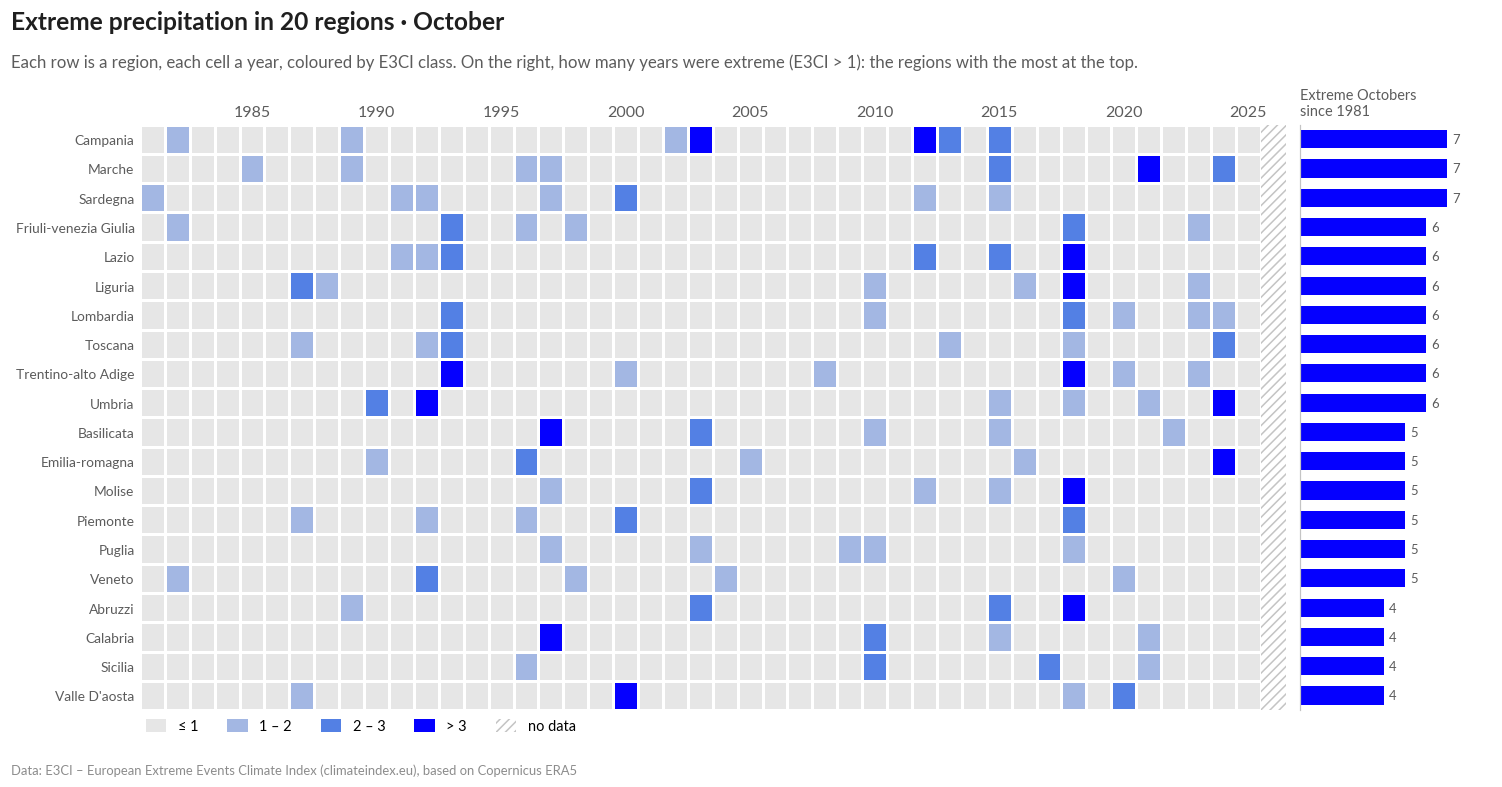

In [ ]:
# Settings of this chart
REGION_COMPONENT = "extreme prec"
REGION_MONTH = 10                     # 1 = January ... 12 = December, 0 = the strongest month of each year
REGION_AREAS = ITALIAN_REGIONS        # the regions to show, or countries (e.g. EUROPE)
TITLE = ""                            # your title between the quotes, or "" for the automatic title

plot_countries_heatmap(REGION_COMPONENT, REGION_MONTH, areas=REGION_AREAS, title=TITLE)


## 💬 For the final discussion
* Which chart would you show to a **mayor**? To a **newspaper reader**? To a **scientist**? Why different ones?
* Which **design choice** changed your perception the most: the type of chart, the threshold, the period, the title?
* What does the E3CI **not** tell us? (people and assets exposed, damages, very local or very short events…)
* Did your titles state a finding, or ask a question? Which works better on social media?

*Notebooks prepared by IFAB for the Visualising Climate 2026 workshop.*
*Data: E3CI – European Extreme Events Climate Index, https://www.climateindex.eu (IFAB; implemented by CMCC and
Leithà – Unipol Group; distributed by Hypermeteo and Radarmeteo), based on Copernicus ERA5.
Neither the European Commission nor ECMWF is responsible for any use of the Copernicus information.
Colours: the E3CI Data Station palette (design by Cinzia Bongino). Country shapes: Natural Earth (public domain).
Font: Lato (SIL Open Font License).*